In [ ]:
import os

if os.path.exists('/content/drive/MyDrive'):
    print('✅ Google Drive is already mounted.')
else:
    print('❌ Google Drive is not mounted.')

✅ Google Drive is already mounted.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, balanced_accuracy_score
)
from sklearn.inspection import permutation_importance

# ── Rutas ────────────────────────────────────────────────────────────
RUTA      = "/content/drive/MyDrive/Proyecto_MapBiomas/"
RUTA_DATA = RUTA + "data_limpia/"
RUTA_FIGS = RUTA + "figuras_modelo/"

import os
os.makedirs(RUTA_FIGS, exist_ok=True)

print('✅ Librerías cargadas')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Librerías cargadas


In [ ]:
import pandas as pd
df = pd.read_csv(RUTA_DATA + "tabla_maestra_final.csv")
print("✅ tabla_maestra_final.csv cargada")
print(f"Filas cargadas: {len(df)}")

✅ tabla_maestra_final.csv cargada
Filas cargadas: 21870


### Carga y fusión de nuevas alertas 2024

A continuación, cargaremos el archivo CSV con las nuevas alertas de 2024 y las fusionaremos con el DataFrame `df` (que contiene todas las alertas anteriores).

In [ ]:
# Cargar el nuevo archivo CSV con alertas de 2024
# ASEGÚRESE de que el nombre del archivo coincida con el que ha proporcionado o el real.
RUTA_NUEVAS_ALERTAS = RUTA_DATA + "alertas_nuevas_2024.csv" # << CAMBIE ESTE NOMBRE DE ARCHIVO SI ES NECESARIO
alertas_2024_nuevas = pd.read_csv(RUTA_NUEVAS_ALERTAS)

print(f"✅ Nuevas alertas 2024 cargadas: {len(alertas_2024_nuevas):,}")

# Fusionar las nuevas alertas con el DataFrame principal (maestra)
df = pd.concat([df, alertas_2024_nuevas], ignore_index=True)

print(f"✅ DataFrame 'df' actualizado con alertas 2024. Total de filas: {len(df):,}")
print(f"Filas para el año 2024 en 'df' después de la carga: {len(df[df['ani_lrt'] == 2024]):,}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/alertas_nuevas_2024.csv'

In [ ]:
import os

print(f"Contents of {RUTA_DATA}:")
for item in os.listdir(RUTA_DATA):
    print(item)

Contents of /content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/:
vias_osm_total.gpkg
vias_osm_total.shp
vias_osm_total.shx
vias_osm_total.dbf
vias_osm_total.cpg
vias_osm_total.prj
vias_filtradas.gpkg
vias_filtradas.shp
vias_filtradas.shx
vias_filtradas.dbf
vias_filtradas.cpg
vias_filtradas.prj
dist_via_distribucion.png
alertas_con_distancia.gpkg
alertas_con_distancia.shp
alertas_con_distancia.dbf
alertas_con_distancia.cpg
alertas_con_distancia.prj
alertas_con_distancia.shx
predicciones.csv
predicciones_v2.csv
dataset_modelo.csv
tabla_maestra_final.csv
tabla_iesa_resultados.csv
tabla_odds_ratios.csv
alertas_2023_predicciones_prospectivas.csv
alertas_2025_predicciones_reducido.csv
alertas_2024_predicciones_enriquecido.csv
alertas_2025_predicciones_enriquecido.csv


In [ ]:
# ── Features seleccionadas ────────────────────────────────────────────
# Continuas
CONTINUAS = ['log_are', 'log_dist_via', 'gini', 'ani_lrt']

# Categóricas → one-hot
CATEGORICAS = ['anp_categoria', 'ti_final', 'tip_lrt', 'dprtmnt', 'clase_T1']

# Binarias (ya son 0/1)
BINARIAS = ['carretera_cerca', 'dentro_ANP_dummy', 'flag_mixta',
            'interaccion_carretera_anp']

# ── Filtro: excluir alertas marcadas como ruido ───────────────────────
# flag_excluir=1 → T-1 no era bosque (ruido de detección)
# flag_sin_T1p=1 → sin T+1 disponible (alertas 2024)
df_modelo = df[
    (df['flag_excluir'] == 0) &
    (df['flag_sin_T1p'] == 0)
].copy()

print(f"Alertas para el modelo: {len(df_modelo):,} "
      f"(descartadas: {len(df) - len(df_modelo):,})")

# ── Encoding one-hot ─────────────────────────────────────────────────
df_encoded = pd.get_dummies(df_modelo[CONTINUAS + CATEGORICAS + BINARIAS],
                             columns=CATEGORICAS, drop_first=False)

X = df_encoded.astype(float)
y = df_modelo['destino']

print(f"X shape: {X.shape}")
print(f"Clases: {sorted(y.unique())}")
print(f"Features: {X.columns.tolist()}")

Alertas para el modelo: 21,870 (descartadas: 0)
X shape: (21870, 36)
Clases: ['D1_agricultura', 'D2b_mineria', 'D3_suelo_expuesto', 'D4_regeneracion', 'D5_bosque']
Features: ['log_are', 'log_dist_via', 'gini', 'ani_lrt', 'carretera_cerca', 'dentro_ANP_dummy', 'flag_mixta', 'interaccion_carretera_anp', 'anp_categoria_buffer_10km', 'anp_categoria_buffer_5km', 'anp_categoria_dentro_intangible', 'anp_categoria_dentro_uso_directo', 'anp_categoria_fuera_anp', 'ti_final_fuera_ti', 'ti_final_ti_en_proceso', 'ti_final_ti_titulada', 'tip_lrt_agriculture', 'tip_lrt_ilegal_mining', 'tip_lrt_mining', 'tip_lrt_others', 'tip_lrt_roads', 'tip_lrt_urban_expansion', 'dprtmnt_Amazonas', 'dprtmnt_Cajamarca', 'dprtmnt_Cusco', 'dprtmnt_Huánuco', 'dprtmnt_Junín', 'dprtmnt_Loreto', 'dprtmnt_Madre de Dios', 'dprtmnt_Pasco', 'dprtmnt_Puno', 'dprtmnt_San Martín', 'dprtmnt_Ucayali', 'clase_T1_bosque_primario', 'clase_T1_formacion_natural', 'clase_T1_vegetacion_secundaria']


In [ ]:
from sklearn.model_selection import train_test_split

# ── Train/test split estratificado ───────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y          # mantiene proporciones de clases en ambos splits
)

print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
print("Distribución en test:")
print(y_test.value_counts().to_string())

# ── Random Forest con balanced ────────────────────────────────────────
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,        # árboles completos
    min_samples_leaf=5,    # evita overfitting en clases pequeñas
    class_weight='balanced',  # compensa el desbalance D1 vs D4
    random_state=42,
    n_jobs=-1              # usa todos los cores de Colab
)

print("\n⏳ Entrenando Random Forest...")
rf.fit(X_train, y_train)
print("✅ Modelo entrenado")

Train: 15,309 | Test: 6,561
Distribución en test:
destino
D1_agricultura       4758
D5_bosque            1342
D3_suelo_expuesto     264
D2b_mineria           183
D4_regeneracion        14

⏳ Entrenando Random Forest...
✅ Modelo entrenado


In [ ]:
y_pred = rf.predict(X_test)

print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, digits=3))

bal_acc = balanced_accuracy_score(y_test, y_pred)
print(f"Balanced accuracy (métrica principal): {bal_acc:.3f}")
print()
print("INTERPRETACIÓN:")
print("  precision = de los que predije como X, ¿cuántos realmente eran X?")
print("  recall    = de los que realmente eran X, ¿cuántos detecté?")
print("  f1-score  = balance entre precisión y recall")
print()
print("  → El recall de D4_regeneracion es el más crítico:")
print("    si es bajo, el modelo 'ignora' la regeneración por ser clase pequeña.")

CLASSIFICATION REPORT
                   precision    recall  f1-score   support

   D1_agricultura      0.881     0.737     0.803      4758
      D2b_mineria      0.788     0.956     0.864       183
D3_suelo_expuesto      0.206     0.534     0.297       264
  D4_regeneracion      0.231     0.429     0.300        14
        D5_bosque      0.538     0.659     0.593      1342

         accuracy                          0.719      6561
        macro avg      0.529     0.663     0.571      6561
     weighted avg      0.780     0.719     0.740      6561

Balanced accuracy (métrica principal): 0.663

INTERPRETACIÓN:
  precision = de los que predije como X, ¿cuántos realmente eran X?
  recall    = de los que realmente eran X, ¿cuántos detecté?
  f1-score  = balance entre precisión y recall

  → El recall de D4_regeneracion es el más crítico:
    si es bajo, el modelo 'ignora' la regeneración por ser clase pequeña.


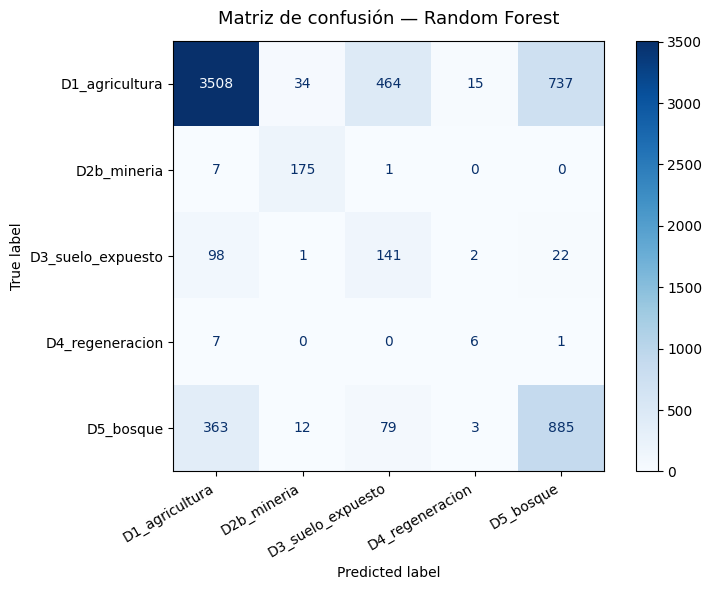

✅ Figura guardada


In [ ]:
clases_orden = ['D1_agricultura', 'D2b_mineria', 'D3_suelo_expuesto',
                'D4_regeneracion', 'D5_bosque']

cm = confusion_matrix(y_test, y_pred, labels=clases_orden)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases_orden)
disp.plot(ax=ax, colorbar=True, cmap='Blues', values_format='d')
ax.set_title('Matriz de confusión — Random Forest', fontsize=13, pad=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'confusion_matrix.png', dpi=300)
plt.show()
print("✅ Figura guardada")

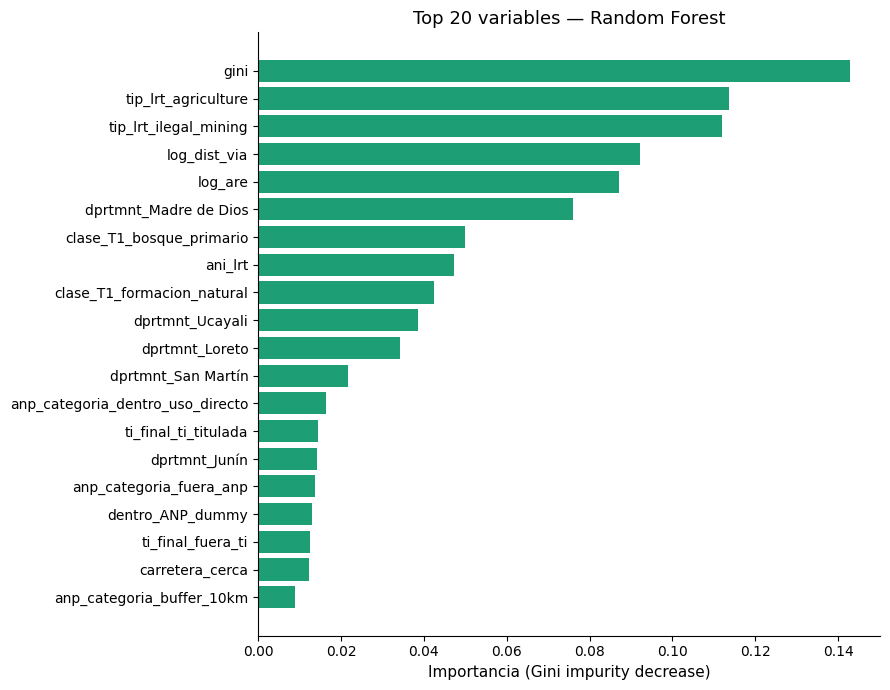

✅ Figura guardada

Top 10 variables más importantes:
  gini                                          0.1430
  tip_lrt_agriculture                           0.1135
  tip_lrt_ilegal_mining                         0.1119
  log_dist_via                                  0.0921
  log_are                                       0.0872
  dprtmnt_Madre de Dios                         0.0761
  clase_T1_bosque_primario                      0.0499
  ani_lrt                                       0.0472
  clase_T1_formacion_natural                    0.0425
  dprtmnt_Ucayali                               0.0385


In [ ]:
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

# Top 20 variables
top20 = importances.head(20)

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(top20.index[::-1], top20.values[::-1], color='#1D9E75', edgecolor='none')
ax.set_xlabel('Importancia (Gini impurity decrease)', fontsize=11)
ax.set_title('Top 20 variables — Random Forest', fontsize=13)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'feature_importance.png', dpi=300)
plt.show()
print("✅ Figura guardada")

print("\nTop 10 variables más importantes:")
for feat, imp in importances.head(10).items():
    print(f"  {feat:<45} {imp:.4f}")

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("⏳ Corriendo validación cruzada 5-fold (puede tardar 2-3 min)...")

scores_bal = cross_val_score(
    rf, X, y,
    cv=cv,
    scoring='balanced_accuracy',
    n_jobs=-1
)

scores_f1 = cross_val_score(
    rf, X, y,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

print("\n=" * 40)
print(f"Balanced accuracy: {scores_bal.mean():.3f} ± {scores_bal.std():.3f}")
print(f"  por fold: {[round(s,3) for s in scores_bal]}")
print()
print(f"F1 macro:          {scores_f1.mean():.3f} ± {scores_f1.std():.3f}")
print(f"  por fold: {[round(s,3) for s in scores_f1]}")
print()
print("INTERPRETACIÓN:")
print("  Balanced accuracy > 0.60 → el modelo discrimina mejor que azar.")
print("  Std bajo (< 0.03)  → resultados estables entre folds.")

⏳ Corriendo validación cruzada 5-fold (puede tardar 2-3 min)...

=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
Balanced accuracy: 0.652 ± 0.047
  por fold: [np.float64(0.638), np.float64(0.721), np.float64(0.578), np.float64(0.652), np.float64(0.673)]

F1 macro:          0.549 ± 0.020
  por fold: [np.float64(0.542), np.float64(0.569), np.float64(0.52), np.float64(0.538), np.float64(0.574)]

INTERPRETACIÓN:
  Balanced accuracy > 0.60 → el modelo discrimina mejor que azar.
  Std bajo (< 0.03)  → resultados estables entre folds.


In [ ]:
# IESA conservador = % alertas con D5_bosque
# IESA amplio      = % alertas con D4_regeneracion O D5_bosque

df_modelo['iesa_conservador'] = (df_modelo['destino'] == 'D5_bosque').astype(int)
df_modelo['iesa_amplio']      = (df_modelo['destino'].isin(['D4_regeneracion','D5_bosque'])).astype(int)
df_modelo['consolidado']      = (df_modelo['destino'].isin(['D1_agricultura','D2b_mineria'])).astype(int)

def tabla_iesa(df, grupo, titulo):
    t = df.groupby(grupo).agg(
        n            = ('destino','count'),
        iesa_conserv = ('iesa_conservador','mean'),
        iesa_amplio  = ('iesa_amplio','mean'),
        consolidado  = ('consolidado','mean')
    ).round(3)
    t['iesa_conserv_%'] = (t['iesa_conserv'] * 100).round(1)
    t['iesa_amplio_%']  = (t['iesa_amplio']  * 100).round(1)
    t['consolid_%']     = (t['consolidado']   * 100).round(1)
    print(f"\n{'='*60}")
    print(f"  {titulo}")
    print(f"{'='*60}")
    print(t[['n','iesa_conserv_%','iesa_amplio_%','consolid_%']].to_string())
    return t

t_anp = tabla_iesa(df_modelo, 'anp_categoria',  'IESA por categoría ANP')
t_ti  = tabla_iesa(df_modelo, 'ti_final',        'IESA por territorio indígena')
t_dep = tabla_iesa(df_modelo, 'dprtmnt',          'IESA por departamento')
t_tip = tabla_iesa(df_modelo, 'tip_lrt',          'IESA por tipo de presión')


  IESA por categoría ANP
                        n  iesa_conserv_%  iesa_amplio_%  consolid_%
anp_categoria                                                       
buffer_10km          2417            22.7           23.0        74.3
buffer_5km           1917            28.6           28.7        68.3
dentro_intangible      21            71.4           71.4        28.6
dentro_uso_directo    427            28.8           31.1        66.0
fuera_anp           17088            18.9           19.1        76.5

  IESA por territorio indígena
                   n  iesa_conserv_%  iesa_amplio_%  consolid_%
ti_final                                                       
fuera_ti       16931            20.8           21.0        75.2
ti_en_proceso    590            20.2           20.3        68.1
ti_titulada     4349            18.9           19.3        76.6

  IESA por departamento
                  n  iesa_conserv_%  iesa_amplio_%  consolid_%
dprtmnt                                            

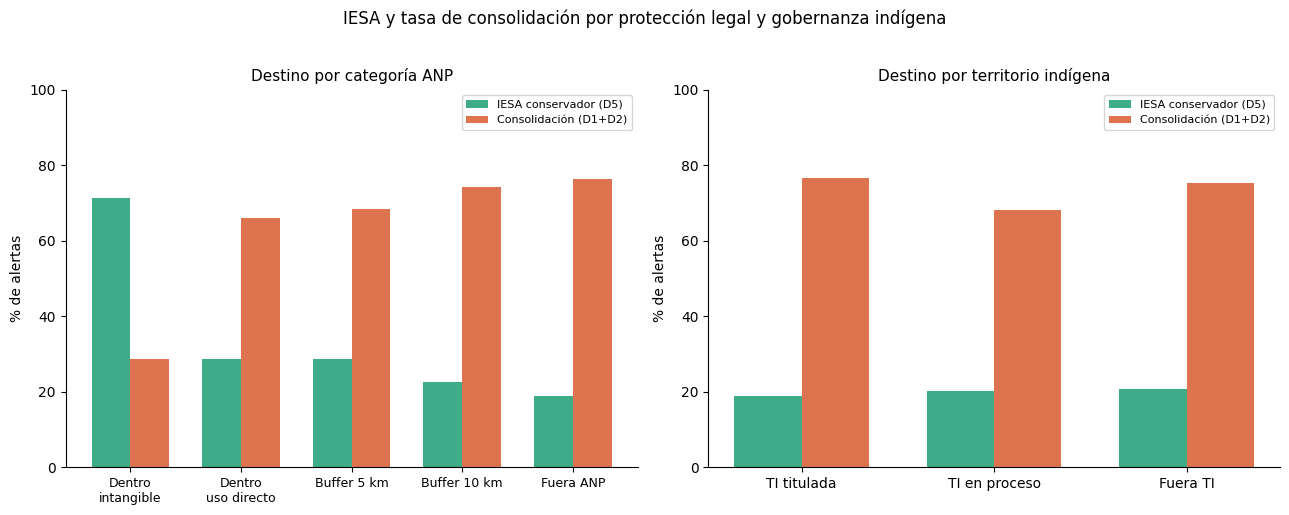

✅ Figura guardada


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Panel izquierdo: IESA por ANP ────────────────────────────────────
orden_anp = ['dentro_intangible','dentro_uso_directo','buffer_5km',
             'buffer_10km','fuera_anp']
etiq_anp  = ['Dentro\nintangible','Dentro\nuso directo',
             'Buffer 5 km','Buffer 10 km','Fuera ANP']

# Calcular por orden
vals_conserv_anp = [t_anp.loc[c,'iesa_conserv_%'] if c in t_anp.index else 0 for c in orden_anp]
vals_consolid_anp = [t_anp.loc[c,'consolid_%']    if c in t_anp.index else 0 for c in orden_anp]

x = np.arange(len(orden_anp))
w = 0.35
axes[0].bar(x - w/2, vals_conserv_anp, w, label='IESA conservador (D5)',
            color='#1D9E75', alpha=0.85)
axes[0].bar(x + w/2, vals_consolid_anp, w, label='Consolidación (D1+D2)',
            color='#D85A30', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(etiq_anp, fontsize=9)
axes[0].set_ylabel('% de alertas', fontsize=10)
axes[0].set_title('Destino por categoría ANP', fontsize=11)
axes[0].legend(fontsize=8)
axes[0].spines[['top','right']].set_visible(False)
axes[0].set_ylim(0, 100)

# ── Panel derecho: IESA por TI ────────────────────────────────────────
orden_ti = ['ti_titulada','ti_en_proceso','fuera_ti']
etiq_ti  = ['TI titulada','TI en proceso','Fuera TI']

vals_conserv_ti  = [t_ti.loc[c,'iesa_conserv_%'] if c in t_ti.index else 0 for c in orden_ti]
vals_consolid_ti = [t_ti.loc[c,'consolid_%']     if c in t_ti.index else 0 for c in orden_ti]

x2 = np.arange(len(orden_ti))
axes[1].bar(x2 - w/2, vals_conserv_ti,  w, color='#1D9E75', alpha=0.85, label='IESA conservador (D5)')
axes[1].bar(x2 + w/2, vals_consolid_ti, w, color='#D85A30', alpha=0.85, label='Consolidación (D1+D2)')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(etiq_ti, fontsize=10)
axes[1].set_ylabel('% de alertas', fontsize=10)
axes[1].set_title('Destino por territorio indígena', fontsize=11)
axes[1].legend(fontsize=8)
axes[1].spines[['top','right']].set_visible(False)
axes[1].set_ylim(0, 100)

fig.suptitle('IESA y tasa de consolidación por protección legal y gobernanza indígena',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'iesa_anp_ti.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura guardada")

In [ ]:
def prob_destino(df, filtro, destino='D1_agricultura'):
    sub = df[filtro]
    if len(sub) == 0:
        return np.nan, 0
    p = (sub['destino'] == destino).mean()
    return round(p, 3), len(sub)

cc  = df_modelo['carretera_cerca'] == 1
scc = df_modelo['carretera_cerca'] == 0
danp = df_modelo['dentro_ANP_dummy'] == 1
fanp = df_modelo['dentro_ANP_dummy'] == 0
tit  = df_modelo['ti_final'] == 'ti_titulada'
proc = df_modelo['ti_final'] == 'ti_en_proceso'
fti  = df_modelo['ti_final'] == 'fuera_ti'

resultados = {
    'Cerca carretera & dentro ANP'   : prob_destino(df_modelo, cc & danp),
    'Cerca carretera & fuera ANP'    : prob_destino(df_modelo, cc & fanp),
    'Sin carretera & dentro ANP'     : prob_destino(df_modelo, scc & danp),
    'Sin carretera & fuera ANP'      : prob_destino(df_modelo, scc & fanp),
    'TI titulada & cerca carretera'  : prob_destino(df_modelo, tit & cc),
    'TI titulada & sin carretera'    : prob_destino(df_modelo, tit & scc),
    'TI en proceso & cerca carretera': prob_destino(df_modelo, proc & cc),
    'Fuera TI & cerca carretera'     : prob_destino(df_modelo, fti & cc),
    'Fuera TI & sin carretera'       : prob_destino(df_modelo, fti & scc),
}

print("P(D1_agricultura | condición)")
print("-" * 55)
for cond, (p, n) in resultados.items():
    print(f"  {cond:<40}  p={p:.3f}  n={n:,}")

P(D1_agricultura | condición)
-------------------------------------------------------
  Cerca carretera & dentro ANP              p=0.689  n=1,782
  Cerca carretera & fuera ANP               p=0.751  n=7,024
  Sin carretera & dentro ANP                p=0.655  n=3,000
  Sin carretera & fuera ANP                 p=0.735  n=10,064
  TI titulada & cerca carretera             p=0.717  n=1,550
  TI titulada & sin carretera               p=0.759  n=2,799
  TI en proceso & cerca carretera           p=0.643  n=221
  Fuera TI & cerca carretera                p=0.746  n=7,035
  Fuera TI & sin carretera                  p=0.705  n=9,896


In [ ]:
from sklearn.linear_model import LogisticRegression
from scipy import stats

# Variable binaria: ¿consolidó? (D1 o D2)
df_modelo['consolidado_bin'] = df_modelo['destino'].isin(
    ['D1_agricultura','D2b_mineria']).astype(int)

# Features para la logística (solo las interpretables directamente)
FEATS_LOG = ['log_are', 'log_dist_via', 'carretera_cerca',
             'dentro_ANP_dummy', 'gini']

# Añadir dummies de ti_final
ti_dummies = pd.get_dummies(df_modelo['ti_final'], prefix='ti', drop_first=True)
X_log = pd.concat([df_modelo[FEATS_LOG].reset_index(drop=True),
                   ti_dummies.reset_index(drop=True)], axis=1).astype(float)
y_log = df_modelo['consolidado_bin'].values

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_log, y_log)

# Calcular OR e IC al 95%
coefs = lr.coef_[0]
n     = len(y_log)
se    = np.sqrt(np.diag(np.linalg.pinv(X_log.T @ X_log))) * (n / (n - X_log.shape[1] - 1)) ** 0.5

OR       = np.exp(coefs)
lower_CI = np.exp(coefs - 1.96 * se)
upper_CI = np.exp(coefs + 1.96 * se)

or_df = pd.DataFrame({
    'variable': X_log.columns,
    'OR':       OR,
    'lower_CI': lower_CI,
    'upper_CI': upper_CI
}).set_index('variable').round(3)

print("Odds Ratios — P(consolidación = D1 o D2)")
print(or_df.to_string())
print()
print("INTERPRETACIÓN:")
print("  OR < 1 → reduce probabilidad de consolidación")
print("  OR > 1 → aumenta probabilidad de consolidación")
print("  SI el IC (lower_CI–upper_CI) NO cruza 1 → estadísticamente significativo")

Odds Ratios — P(consolidación = D1 o D2)
                     OR  lower_CI  upper_CI
variable                                   
log_are           1.486     1.464     1.509
log_dist_via      1.023     1.011     1.035
carretera_cerca   1.030     0.996     1.065
dentro_ANP_dummy  0.787     0.763     0.813
gini              0.512     0.477     0.550
ti_ti_en_proceso  0.674     0.621     0.732
ti_ti_titulada    1.217     1.177     1.259

INTERPRETACIÓN:
  OR < 1 → reduce probabilidad de consolidación
  OR > 1 → aumenta probabilidad de consolidación
  SI el IC (lower_CI–upper_CI) NO cruza 1 → estadísticamente significativo


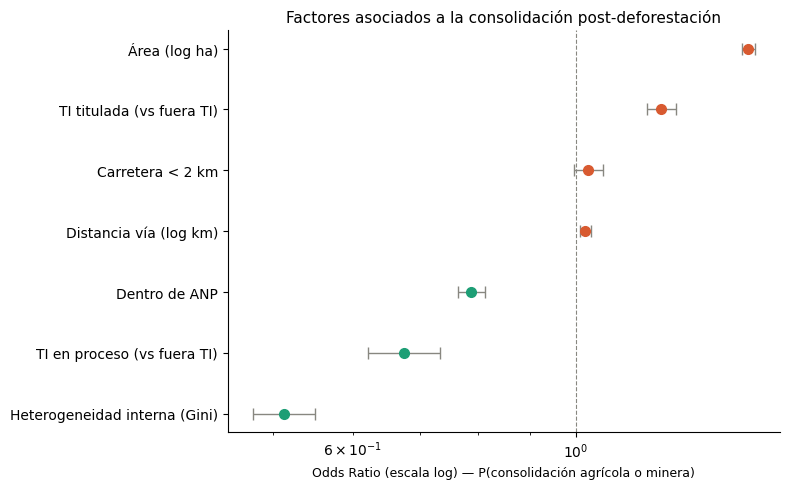

✅ Figura guardada


In [ ]:
etiquetas = {
    'log_are':           'Área (log ha)',
    'log_dist_via':      'Distancia vía (log km)',
    'carretera_cerca':   'Carretera < 2 km',
    'dentro_ANP_dummy':  'Dentro de ANP',
    'gini':              'Heterogeneidad interna (Gini)',
    'ti_ti_en_proceso':  'TI en proceso (vs fuera TI)',
    'ti_ti_titulada':    'TI titulada (vs fuera TI)',
}

plot_df = or_df.copy()
plot_df['label'] = plot_df.index.map(lambda x: etiquetas.get(x, x))
plot_df = plot_df.sort_values('OR')

fig, ax = plt.subplots(figsize=(8, 5))

for i, (idx, row) in enumerate(plot_df.iterrows()):
    color = '#D85A30' if row['OR'] > 1 else '#1D9E75'
    ax.errorbar(
        x=row['OR'], y=i,
        xerr=[[row['OR'] - row['lower_CI']], [row['upper_CI'] - row['OR']]],
        fmt='o', color=color, ecolor='#888780',
        capsize=4, markersize=7, elinewidth=1
    )

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df['label'], fontsize=10)
ax.axvline(1, color='#888780', linestyle='--', linewidth=0.8)
ax.set_xscale('log')
ax.set_xlabel('Odds Ratio (escala log) — P(consolidación agrícola o minera)', fontsize=9)
ax.set_title('Factores asociados a la consolidación post-deforestación', fontsize=11)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'odds_ratios.png', dpi=300)
plt.show()
print("✅ Figura guardada")

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators':    [200, 300, 500],
    'max_depth':       [10, 20, None],
    'min_samples_leaf':[3, 5, 10],
    'max_features':    ['sqrt', 'log2', 0.5],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=20,
    scoring='balanced_accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    verbose=1,
    n_jobs=-1
)

print("⏳ RandomizedSearchCV (puede tardar 5-10 min en Colab)...")
rf_search.fit(X_train, y_train)

print(f"\n✅ Mejores parámetros: {rf_search.best_params_}")
print(f"   Balanced accuracy CV: {rf_search.best_score_:.3f}")

# Evaluar el mejor modelo
y_pred_best = rf_search.best_estimator_.predict(X_test)
print("\nClassification report con mejor modelo:")
print(classification_report(y_test, y_pred_best, digits=3))

⏳ RandomizedSearchCV (puede tardar 5-10 min en Colab)...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

✅ Mejores parámetros: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}
   Balanced accuracy CV: 0.651

Classification report con mejor modelo:
                   precision    recall  f1-score   support

   D1_agricultura      0.894     0.611     0.725      4758
      D2b_mineria      0.730     0.962     0.830       183
D3_suelo_expuesto      0.161     0.731     0.264       264
  D4_regeneracion      0.160     0.571     0.250        14
        D5_bosque      0.499     0.677     0.575      1342

         accuracy                          0.639      6561
        macro avg      0.489     0.710     0.529      6561
     weighted avg      0.777     0.639     0.678      6561



In [ ]:
# Tabla resumen IESA para el paper
resumen = []
for grupo, df_g in [('anp_categoria', t_anp), ('ti_final', t_ti),
                    ('dprtmnt', t_dep), ('tip_lrt', t_tip)]:
    df_g['grupo'] = grupo
    df_g['categoria'] = df_g.index
    resumen.append(df_g[['grupo','categoria','n','iesa_conserv_%','iesa_amplio_%','consolid_%']])

tabla_final = pd.concat(resumen)
tabla_final.to_csv(RUTA_DATA + "tabla_iesa_resultados.csv", index=False)

# Tabla OR para el paper
or_df['label'] = or_df.index.map(lambda x: etiquetas.get(x, x))
or_df.to_csv(RUTA_DATA + "tabla_odds_ratios.csv")

print("✅ Tablas exportadas:")
print("   tabla_iesa_resultados.csv")
print("   tabla_odds_ratios.csv")
print()
print("Figuras generadas en", RUTA_FIGS)
print("   confusion_matrix.png")
print("   feature_importance.png")
print("   iesa_anp_ti.png")
print("   odds_ratios.png")

✅ Tablas exportadas:
   tabla_iesa_resultados.csv
   tabla_odds_ratios.csv

Figuras generadas en /content/drive/MyDrive/Proyecto_MapBiomas/figuras_modelo/
   confusion_matrix.png
   feature_importance.png
   iesa_anp_ti.png
   odds_ratios.png


In [ ]:
tabla_cruce = pd.crosstab(
    df_modelo['ti_final'],
    df_modelo['tip_lrt'],
    normalize='index'
).round(3) * 100

print("% de cada tipo de presión dentro de cada categoría TI:")
print(tabla_cruce.to_string())

# También el destino controlando por tipo de presión
for presion in ['agriculture', 'ilegal_mining']:
    sub = df_modelo[df_modelo['tip_lrt'] == presion]
    print(f"\n── Solo '{presion}' (n={len(sub):,}) ──")
    t = sub.groupby('ti_final')['destino'].value_counts(normalize=True).unstack().fillna(0).round(3) * 100
    print(t.to_string())

% de cada tipo de presión dentro de cada categoría TI:
tip_lrt        agriculture  ilegal_mining  mining  others  roads  urban_expansion
ti_final                                                                         
fuera_ti              96.6            2.8     0.1     0.1    0.3              0.1
ti_en_proceso         99.5            0.0     0.0     0.0    0.3              0.2
ti_titulada           97.3            2.2     0.0     0.0    0.3              0.1

── Solo 'agriculture' (n=21,178) ──
destino        D1_agricultura  D2b_mineria  D3_suelo_expuesto  D4_regeneracion  D5_bosque
ti_final                                                                                 
fuera_ti                 74.4          0.3                3.9              0.2       21.3
ti_en_proceso            68.1          0.0               11.6              0.2       20.1
ti_titulada              76.2          0.2                4.1              0.4       19.2

── Solo 'ilegal_mining' (n=565) ──
destino     

In [ ]:
from scipy.stats import mannwhitneyu, kruskal

# ¿La distancia a vías es distinta entre consolidación y regeneración?
consolid = df_modelo[df_modelo['consolidado'] == 1]['dist_via_km']
regen    = df_modelo[df_modelo['iesa_conservador'] == 1]['dist_via_km']

stat, p = mannwhitneyu(consolid, regen, alternative='two-sided')
print(f"Mann-Whitney dist_via_km (consolid vs bosque):")
print(f"  Media consolid: {consolid.mean():.2f} km | Media bosque: {regen.mean():.2f} km")
print(f"  U={stat:.0f}, p={p:.4f}")
print(f"  → {'Diferencia significativa' if p < 0.05 else 'Sin diferencia significativa'}")

# Kruskal-Wallis área por destino
grupos = [df_modelo[df_modelo['destino']==d]['area_ha'] for d in df_modelo['destino'].unique()]
stat_k, p_k = kruskal(*grupos)
print(f"\nKruskal-Wallis área por destino: H={stat_k:.1f}, p={p_k:.4f}")

Mann-Whitney dist_via_km (consolid vs bosque):
  Media consolid: 6.37 km | Media bosque: 6.18 km
  U=37029503, p=0.5806
  → Sin diferencia significativa

Kruskal-Wallis área por destino: H=347.8, p=0.0000


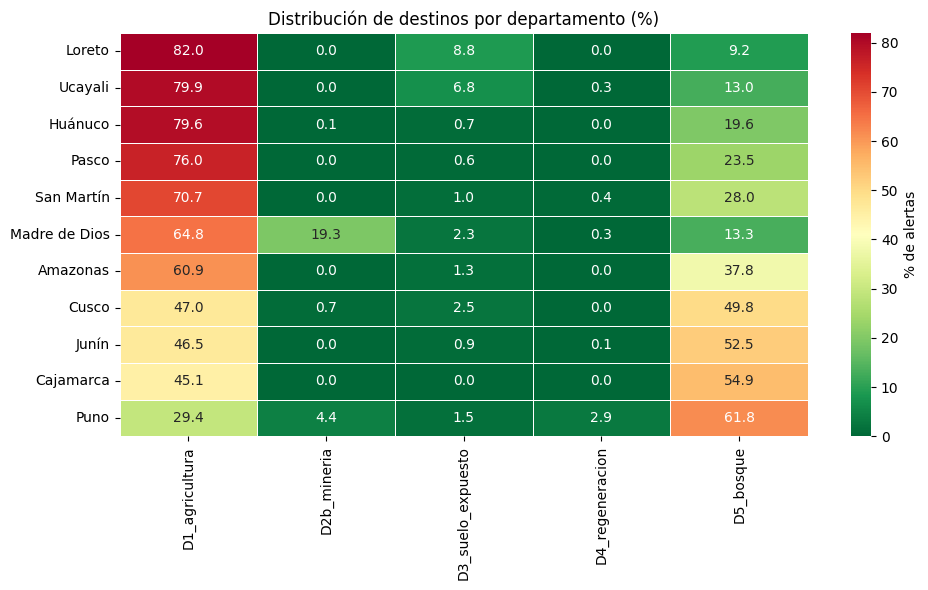

✅ Figura guardada


In [ ]:
pivot = pd.crosstab(
    df_modelo['dprtmnt'],
    df_modelo['destino'],
    normalize='index'
).round(3) * 100

# Ordenar por tasa de consolidación
pivot = pivot.sort_values('D1_agricultura', ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='RdYlGn_r',
            linewidths=0.5, ax=ax, cbar_kws={'label': '% de alertas'})
ax.set_title('Distribución de destinos por departamento (%)', fontsize=12)
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'heatmap_destinos_departamento.png', dpi=300)
plt.show()
print("✅ Figura guardada")

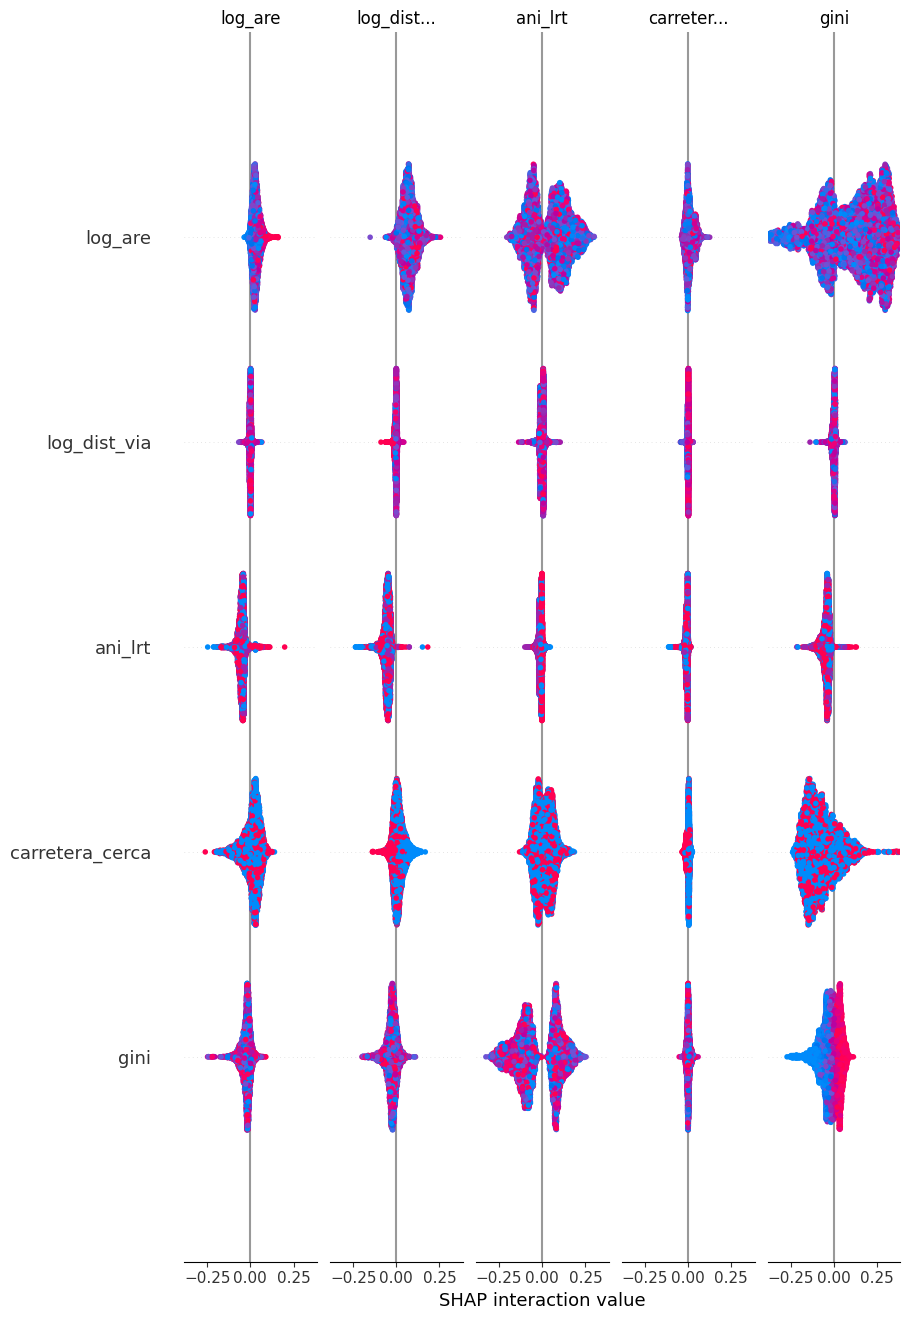

In [ ]:
!pip install shap

import shap
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# Beeswarm plot — la figura que va al paper
shap.summary_plot(shap_values, X_test, class_names=rf.classes_,
                  max_display=15, show=False)
plt.savefig(RUTA_FIGS + 'shap_beeswarm.png', dpi=300, bbox_inches='tight')

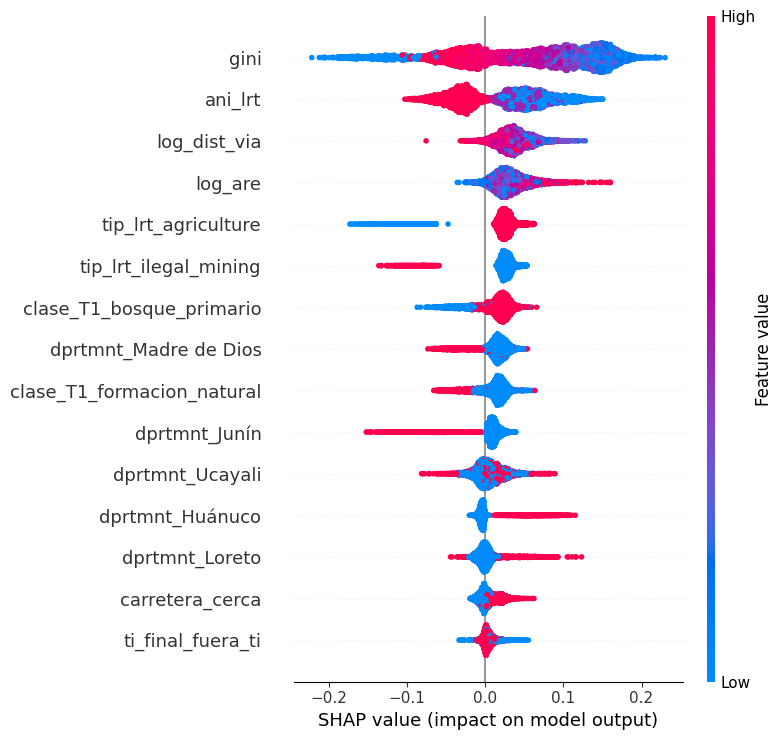

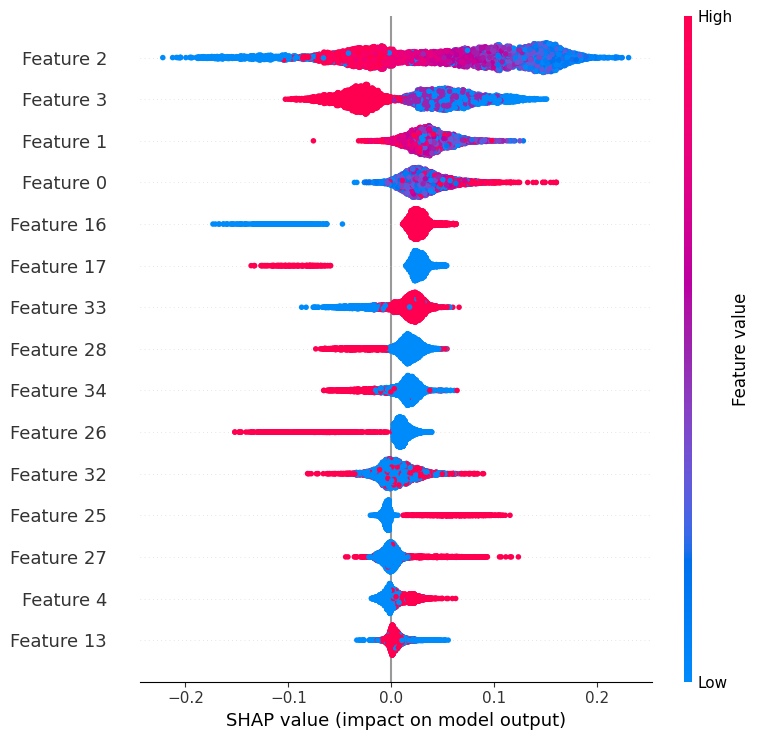

In [ ]:
import shap

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# Antes del summary_plot, asegúrate de pasar feature_names explícitamente
shap.summary_plot(
    shap_values[:, :, idx_d1], # Slicing corregido para obtener la clase D1
    X_test.values,             # Convertir X_test a array de NumPy
    feature_names=X_test.columns.tolist(),
    max_display=15,
    show=False
)

plt.savefig(RUTA_FIGS + 'shap_summary_bar.png', dpi=300, bbox_inches='tight')
plt.show()

# Y este para D1_agricultura específicamente (tu clase principal)
idx_d1 = list(rf.classes_).index('D1_agricultura')
shap.summary_plot(
    shap_values[:, :, idx_d1],  # solo la clase D1
    X_test.values,        # Convertir X_test a array de NumPy
    max_display=15,
    show=False
)
plt.savefig(RUTA_FIGS + 'shap_d1_agricultura.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import os

# List the contents of the RUTA_DATA directory
print(f"Contents of {RUTA_DATA}:")
for item in os.listdir(RUTA_DATA):
    print(item)

Contents of /content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/:
vias_osm_total.gpkg
vias_osm_total.shp
vias_osm_total.shx
vias_osm_total.dbf
vias_osm_total.cpg
vias_osm_total.prj
vias_filtradas.gpkg
vias_filtradas.shp
vias_filtradas.shx
vias_filtradas.dbf
vias_filtradas.cpg
vias_filtradas.prj
dist_via_distribucion.png
alertas_con_distancia.gpkg
alertas_con_distancia.shp
alertas_con_distancia.dbf
alertas_con_distancia.cpg
alertas_con_distancia.prj
alertas_con_distancia.shx
predicciones.csv
predicciones_v2.csv
dataset_modelo.csv
tabla_maestra_final.csv
tabla_iesa_resultados.csv
tabla_odds_ratios.csv


In [ ]:
import geopandas as gpd

# Cargar shapefile con geometría
gdf = gpd.read_file(RUTA_DATA + "alertas_con_distancia.gpkg")
gdf = gdf.to_crs("EPSG:32718")  # UTM para metros reales

# Buffer de 5 km alrededor de cada alerta
buffer_5km = gdf.copy()
buffer_5km['geometry'] = gdf.geometry.centroid.buffer(5000)

# Contar alertas vecinas dentro del buffer (excluyendo la propia)
joined = gpd.sjoin(gdf[['alert_d','geometry']],
                   buffer_5km[['alert_d','geometry']],
                   how='left', predicate='within')
densidad = joined[joined['alert_d_left'] != joined['alert_d_right']]\
           .groupby('alert_d_left').size().reset_index()
densidad.columns = ['alert_d', 'n_alertas_5km']

gdf = gdf.merge(densidad, on='alert_d', how='left')
gdf['n_alertas_5km'] = gdf['n_alertas_5km'].fillna(0)

In [ ]:
import geopandas as gpd

# Ensure gdf has the 'ani_lrt' (year of alert) column by merging from df_modelo
# This is necessary for temporal filtering.
# Ensure 'alert_d' columns are of the same type for a successful merge
gdf['alert_d'] = gdf['alert_d'].astype(int)

# Drop 'ani_lrt' from gdf if it exists to avoid merge conflicts
if 'ani_lrt' in gdf.columns:
    gdf = gdf.drop(columns=['ani_lrt'])

df_modelo_temp = df_modelo[['alert_d', 'ani_lrt']].copy()
df_modelo_temp['alert_d'] = df_modelo_temp['alert_d'].astype(int)
gdf = gdf.merge(df_modelo_temp, on='alert_d', how='left')

# Create buffers around each alert. These buffers will be used to find neighbors.
gdf_buffers = gdf.copy()
gdf_buffers['geometry'] = gdf.geometry.centroid.buffer(5000) # 5 km buffer

# Prepare left DataFrame for spatial join with explicit column names
gdf_buffers_left = gdf_buffers[['alert_d', 'ani_lrt', 'geometry']].rename(
    columns={'alert_d': 'alert_d_buffer', 'ani_lrt': 'ani_lrt_buffer'}
)

# Prepare right DataFrame for spatial join with explicit column names
gdf_right = gdf[['alert_d', 'ani_lrt', 'geometry']].rename(
    columns={'alert_d': 'alert_d_point', 'ani_lrt': 'ani_lrt_point'}
)

# Perform a spatial join between the buffers (left) and the original alerts (right).
# This finds all alerts that fall within any buffer.
joined_alerts = gpd.sjoin(
    gdf_buffers_left, # Buffers with explicitly named alert_d_buffer and ani_lrt_buffer
    gdf_right,        # Alerts (points) with explicitly named alert_d_point and ani_lrt_point
    how='inner', predicate='intersects'
)

# Filter the joined results:
# 1. Exclude the alert itself (an alert cannot be its own neighbor).
# 2. Only include neighbor alerts whose year ('ani_lrt_point') is 1 or 2 years prior
#    to the current alert's year ('ani_lrt_buffer').
density_filtered = joined_alerts[
    (joined_alerts['alert_d_buffer'] != joined_alerts['alert_d_point']) &
    (
        (joined_alerts['ani_lrt_point'] == joined_alerts['ani_lrt_buffer'] - 1) |
        (joined_alerts['ani_lrt_point'] == joined_alerts['ani_lrt_buffer'] - 2)
    )
]

# Count the number of filtered neighbors for each alert_d_buffer (the original alert).
densidad_alertas_2yr_prev = density_filtered.groupby('alert_d_buffer').size().reset_index(name='n_alertas_5km_2yr_prev')

# Merge this new density feature back into the main df_modelo DataFrame.
# Alerts that had no neighbors in the specified time frame will have NaN, which we fill with 0.
df_modelo = df_modelo.merge(
    densidad_alertas_2yr_prev,
    left_on='alert_d',
    right_on='alert_d_buffer',
    how='left'
)
df_modelo['n_alertas_5km_2yr_prev'] = df_modelo['n_alertas_5km_2yr_prev'].fillna(0).astype(int)

print("✅ Nueva característica 'n_alertas_5km_2yr_prev' agregada a df_modelo.")
print(f"Primeras filas de df_modelo con la nueva característica:\n{df_modelo[['alert_d', 'ani_lrt', 'n_alertas_5km_2yr_prev']].head()}")

✅ Nueva característica 'n_alertas_5km_2yr_prev' agregada a df_modelo.
Primeras filas de df_modelo con la nueva característica:
    alert_d  ani_lrt  n_alertas_5km_2yr_prev
0  10028338   2022.0                       0
1  10043814   2023.0                       2
2  10042219   2023.0                      12
3  10028081   2022.0                      17
4  10007169   2021.0                       0


In [ ]:
# Agregar n_alertas_5km_2yr_prev a las features
CONTINUAS_V2 = ['log_are', 'log_dist_via', 'gini', 'ani_lrt',
                 'n_alertas_5km_2yr_prev']  # ← nueva

df_encoded_v2 = pd.get_dummies(
    df_modelo[CONTINUAS_V2 + CATEGORICAS + BINARIAS],
    columns=CATEGORICAS, drop_first=False
)

X_v2 = df_encoded_v2.astype(float)
y_v2 = df_modelo['destino']

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2, y_v2, test_size=0.3, random_state=42, stratify=y_v2
)

rf_v2 = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_v2.fit(X_train_v2, y_train_v2)
y_pred_v2 = rf_v2.predict(X_test_v2)

bal_v2 = balanced_accuracy_score(y_test_v2, y_pred_v2)
print(f"Balanced accuracy V1 (sin densidad): 0.663")
print(f"Balanced accuracy V2 (con densidad): {bal_v2:.3f}")
print(f"Diferencia: {bal_v2 - 0.663:+.3f}")
print()
print(classification_report(y_test_v2, y_pred_v2, digits=3))

# Importancia de n_alertas_5km en el nuevo modelo
imp_v2 = pd.Series(rf_v2.feature_importances_, index=X_v2.columns)
rank = imp_v2.rank(ascending=False)
print(f"\nRanking de n_alertas_5km_2yr_prev: #{int(rank['n_alertas_5km_2yr_prev'])} de {len(imp_v2)}")
print(f"Importancia: {imp_v2['n_alertas_5km_2yr_prev']:.4f}")

Balanced accuracy V1 (sin densidad): 0.663
Balanced accuracy V2 (con densidad): 0.649
Diferencia: -0.014

                   precision    recall  f1-score   support

   D1_agricultura      0.879     0.761     0.816      4758
      D2b_mineria      0.804     0.962     0.876       183
D3_suelo_expuesto      0.231     0.504     0.317       264
  D4_regeneracion      0.200     0.357     0.256        14
        D5_bosque      0.549     0.663     0.601      1342

         accuracy                          0.736      6561
        macro avg      0.533     0.649     0.573      6561
     weighted avg      0.782     0.736     0.752      6561


Ranking de n_alertas_5km_2yr_prev: #6 de 37
Importancia: 0.0753


In [ ]:
print(df.columns.tolist())

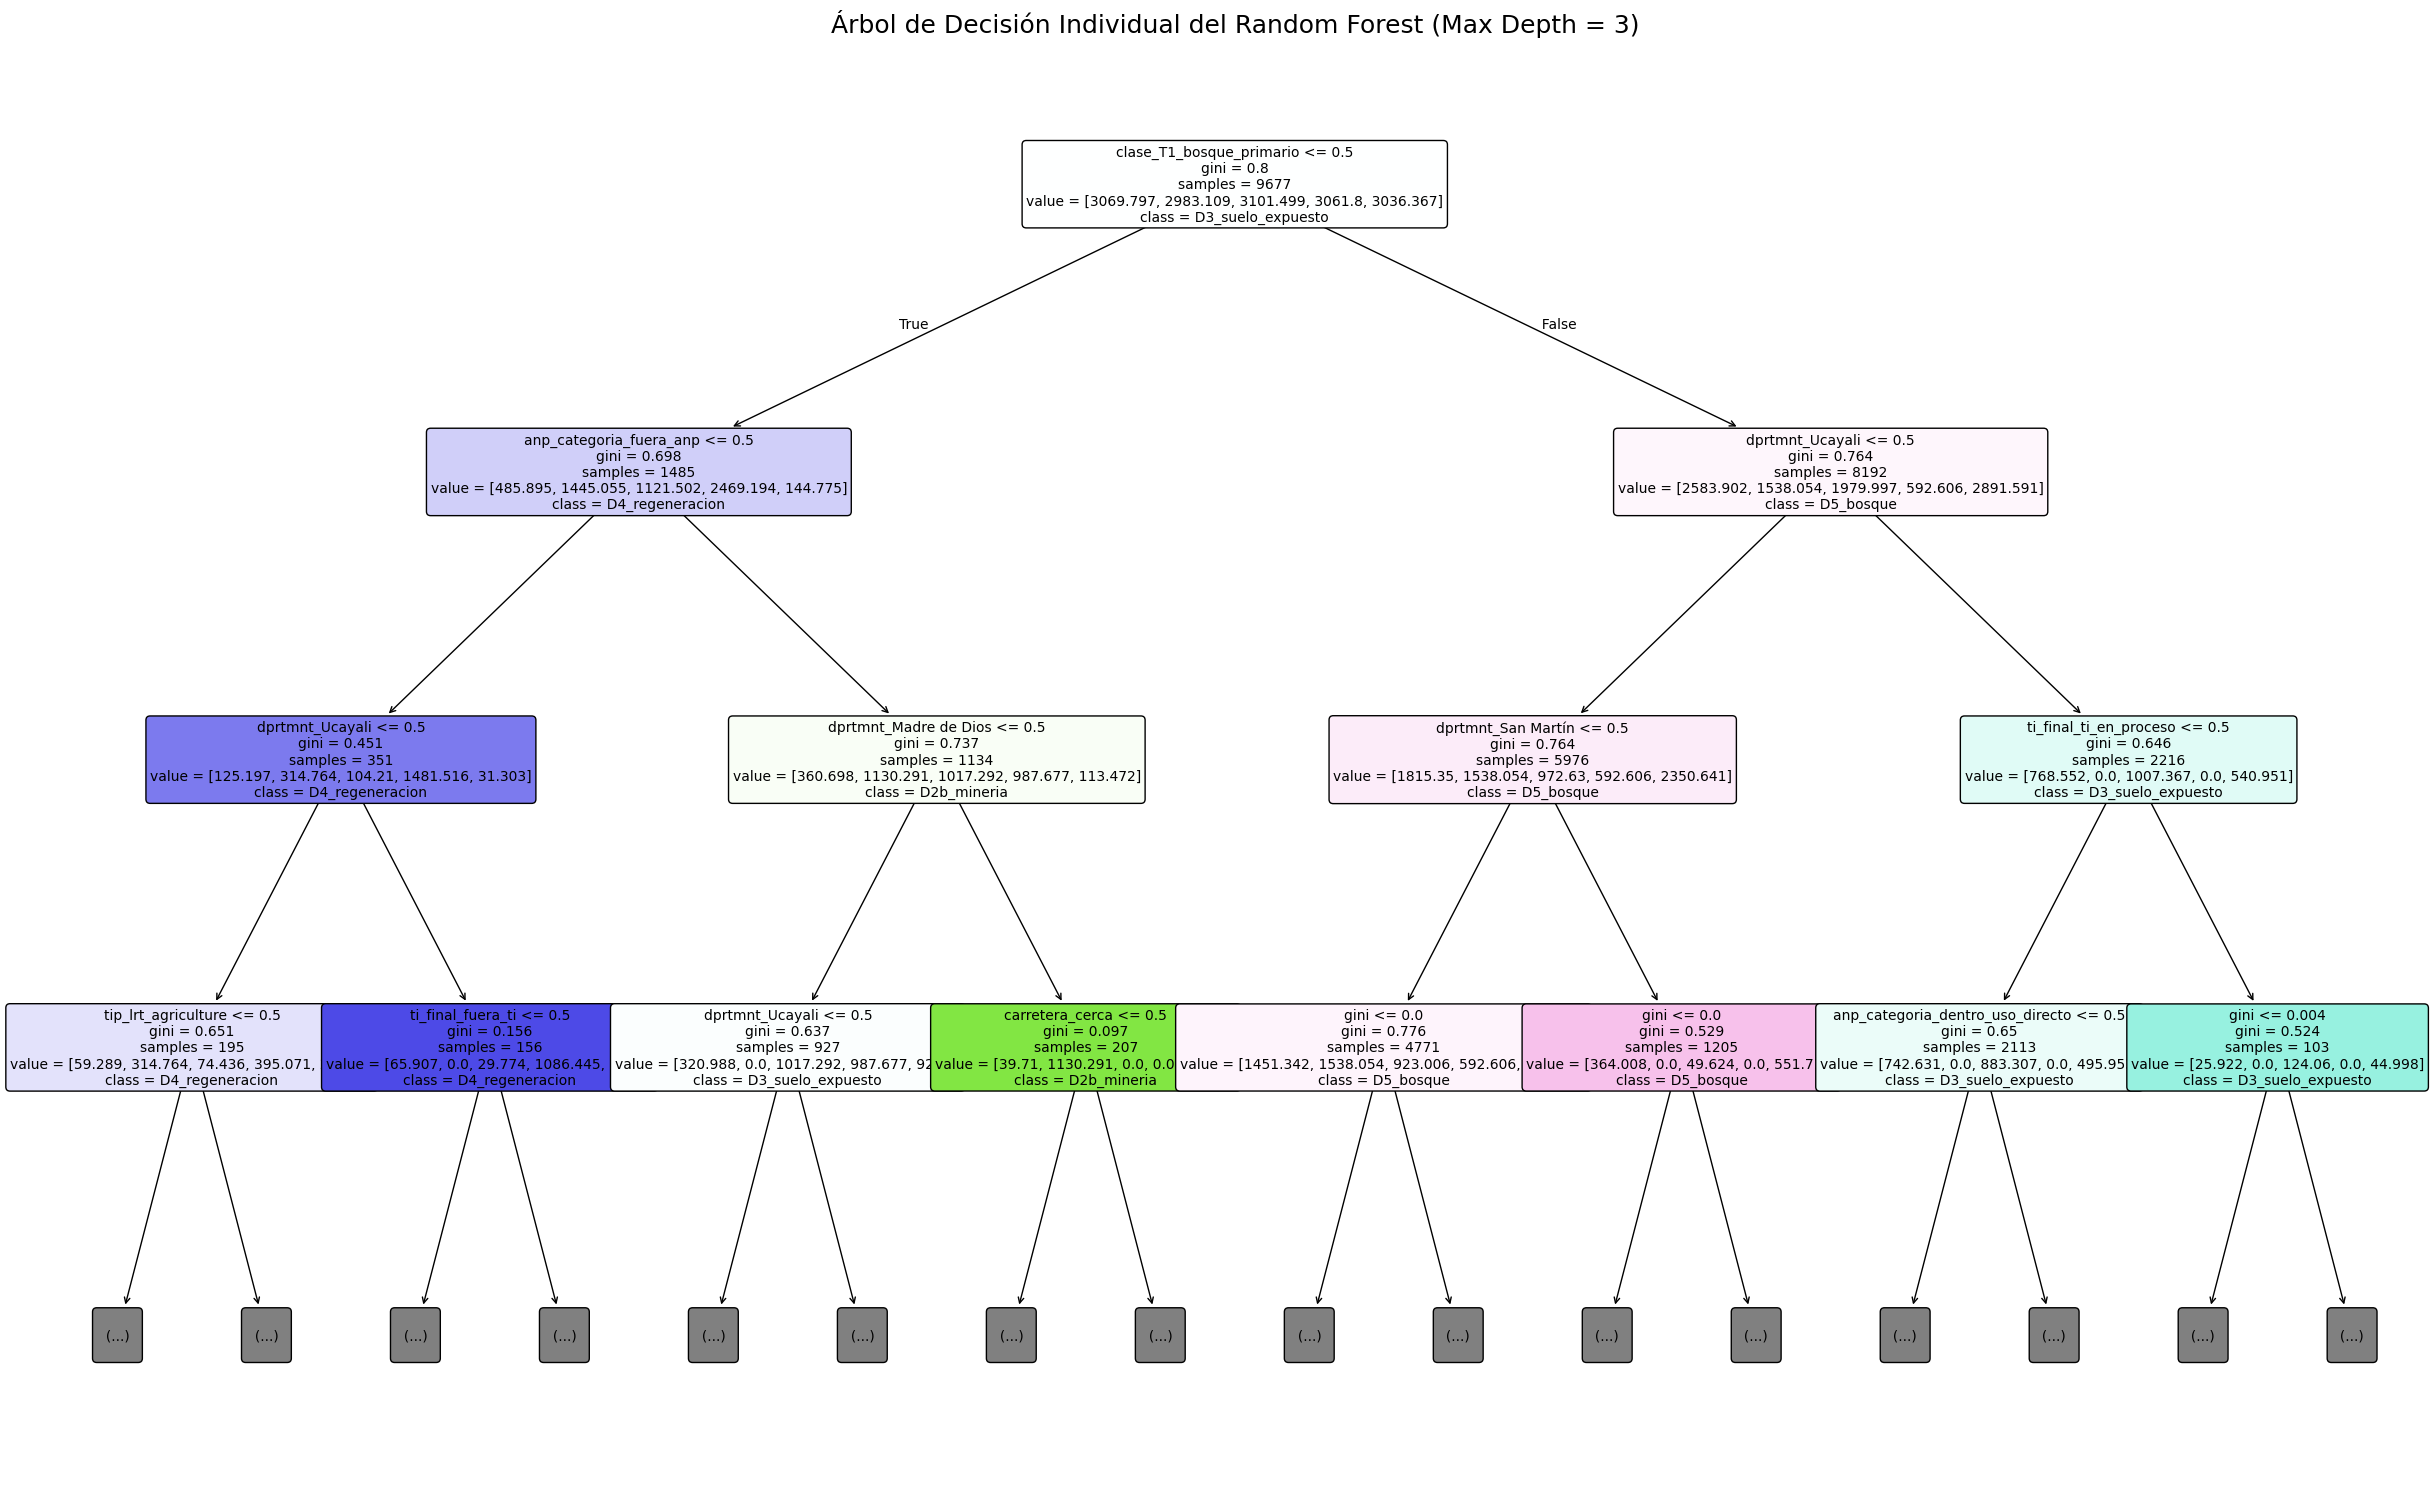

✅ Figura guardada: random_forest_individual_tree_simple.png


In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Seleccionar un árbol del Random Forest (por ejemplo, el primer árbol)
tree_estimator = rf.estimators_[0]

# Obtener los nombres de las características y las clases
feature_names = X.columns.tolist()
class_names = rf.classes_.tolist()

plt.figure(figsize=(25, 15))
plot_tree(
    tree_estimator,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3 # Limitamos la profundidad para una visualización más simple
)
plt.title('Árbol de Decisión Individual del Random Forest (Max Depth = 3)', fontsize=18)
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'random_forest_individual_tree_simple.png', dpi=300)
plt.show()
print("✅ Figura guardada: random_forest_individual_tree_simple.png")

# ANÁLISIS T+2 Y T+3

In [ ]:
# ══════════════════════════════════════════════════════════════
# CELDA 1 — CARGA Y MERGE
# ══════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import chi2_contingency
import warnings
warnings.filterwarnings('ignore')

RUTA      = "/content/drive/MyDrive/Proyecto_MapBiomas/"
RUTA_DATA = RUTA + "data_limpia/"
RUTA_FIGS = RUTA + "figuras_modelo/"

t2t3    = pd.read_csv(RUTA + "alertas_2021_T2_T3.csv")
maestra = pd.read_csv(RUTA_DATA + "tabla_maestra_final.csv")

t2t3 = t2t3.rename(columns={'destino': 'destino_T1'})

# FIX: ani_lrt es float → comparar con 2021.0
maestra_2021 = maestra[maestra['ani_lrt'] == 2021.0].copy()

cols_extra = ['alert_d', 'anp_categoria', 'ti_final',
              'carretera_cerca', 'dentro_ANP_dummy']

df_2021_traj = t2t3.merge(
    maestra_2021[cols_extra],
    on='alert_d', how='left'
)

# Filtrar sin_dato en los tres momentos
df_2021_traj = df_2021_traj[
    (df_2021_traj['destino_T1'] != 'sin_dato') &
    (df_2021_traj['destino_T2'] != 'sin_dato') &
    (df_2021_traj['destino_T3'] != 'sin_dato')
].copy()

print(f"✅ Alertas 2021 con trayectoria completa: {len(df_2021_traj):,}")
print(f"\nT+1 (2022): {df_2021_traj['destino_T1'].value_counts().to_dict()}")
print(f"T+2 (2023): {df_2021_traj['destino_T2'].value_counts().to_dict()}")
print(f"T+3 (2024): {df_2021_traj['destino_T3'].value_counts().to_dict()}")

✅ Alertas 2021 con trayectoria completa: 7,768

T+1 (2022): {'D1_agricultura': 5760, 'D5_bosque': 1588, 'D3_suelo_expuesto': 207, 'D2b_mineria': 146, 'otros': 40, 'D4_regeneracion': 27}
T+2 (2023): {'D1_agricultura': 5938, 'D5_bosque': 1407, 'D2b_mineria': 168, 'otros': 128, 'D3_suelo_expuesto': 127}
T+3 (2024): {'D1_agricultura': 6077, 'D5_bosque': 1266, 'D2b_mineria': 174, 'D3_suelo_expuesto': 136, 'otros': 115}


In [ ]:
n_antes = len(df_2021_traj)

df_2021_traj = df_2021_traj[
    ~df_2021_traj['destino_T1'].isin(['otros']) &
    ~df_2021_traj['destino_T2'].isin(['otros']) &
    ~df_2021_traj['destino_T3'].isin(['otros'])
].copy()

n_filtradas = n_antes - len(df_2021_traj)
print(f"Alertas filtradas ('otros'): {n_filtradas} ({n_filtradas/n_antes*100:.1f}%)")
print(f"Alertas para análisis final: {len(df_2021_traj):,}")

Alertas filtradas ('otros'): 170 (2.2%)
Alertas para análisis final: 7,598


In [ ]:
# ══════════════════════════════════════════════════════════════
# CELDA 2 — CLASIFICAR TRAYECTORIAS
# ══════════════════════════════════════════════════════════════
CONSOLID = {'D1_agricultura', 'D2b_mineria'}
RECUPER  = {'D4_regeneracion', 'D5_bosque'}
TRANSIT  = {'D3_suelo_expuesto'}

def clasificar_trayectoria(row):
    t1, t2, t3 = row['destino_T1'], row['destino_T2'], row['destino_T3']

    if t1 in CONSOLID and t2 in CONSOLID:
        return 'A_consolidacion_rapida'
    if t1 in TRANSIT and t2 in CONSOLID:
        return 'B_consolidacion_progresiva'
    if t1 in TRANSIT and t2 in TRANSIT and t3 in CONSOLID:
        return 'C_consolidacion_tardia'
    if t1 in RECUPER and t2 in RECUPER and t3 in RECUPER:
        return 'D_recuperacion_sostenida'
    if t1 in TRANSIT and t2 in RECUPER:
        return 'E_recuperacion_post_transito'
    if t1 in CONSOLID and t2 in RECUPER:
        return 'F_reversion_post_uso'
    return 'G_trayectoria_inestable'

df_2021_traj['trayectoria'] = df_2021_traj.apply(clasificar_trayectoria, axis=1)

tray_counts = df_2021_traj['trayectoria'].value_counts()
tray_pct    = (tray_counts / len(df_2021_traj) * 100).round(1)

print("═" * 55)
print("DISTRIBUCIÓN DE TRAYECTORIAS (alertas 2021)")
print("═" * 55)
for t, n in tray_counts.items():
    print(f"  {t:<40} {n:>5,}  ({tray_pct[t]:.1f}%)")
print(f"\n  TOTAL: {len(df_2021_traj):,}")

═══════════════════════════════════════════════════════
DISTRIBUCIÓN DE TRAYECTORIAS (alertas 2021)
═══════════════════════════════════════════════════════
  A_consolidacion_rapida                   5,818  (76.6%)
  D_recuperacion_sostenida                 1,230  (16.2%)
  G_trayectoria_inestable                    413  (5.4%)
  B_consolidacion_progresiva                 103  (1.4%)
  C_consolidacion_tardia                      25  (0.3%)
  F_reversion_post_uso                         7  (0.1%)
  E_recuperacion_post_transito                 2  (0.0%)

  TOTAL: 7,598


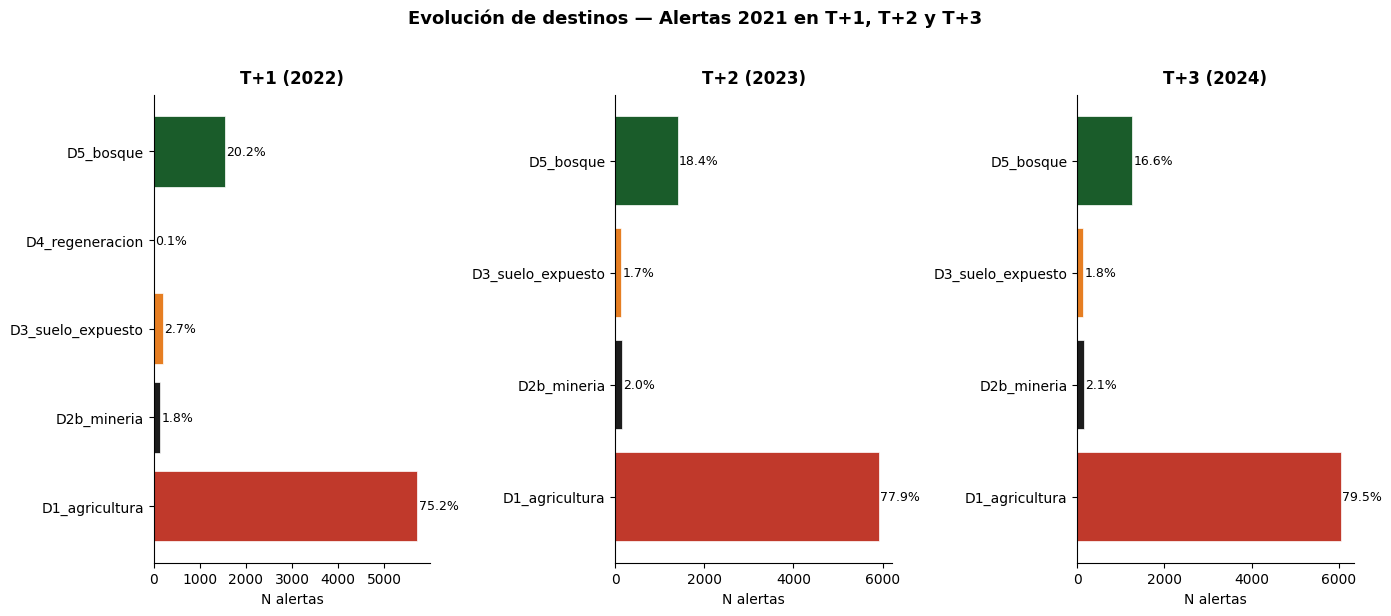

✅ Figura guardada


In [ ]:
import matplotlib.patches as mpatches

# ══════════════════════════════════════════════════════════════
# CELDA 3 — FIGURA: SANKEY SIMPLIFICADO (flujo de destinos)
# Muestra cómo fluyen las alertas entre T+1, T+2 y T+3
# ══════════════════════════════════════════════════════════════
COLORES = {
    'D1_agricultura'   : '#C0392B',
    'D2b_mineria'      : '#1C1C1C',
    'D3_suelo_expuesto': '#E67E22',
    'D4_regeneracion'  : '#27AE60',
    'D5_bosque'        : '#1A5C2A',
    'otros'            : '#AAAAAA'
}
ORDEN = ['D1_agricultura','D2b_mineria','D3_suelo_expuesto',
         'D4_regeneracion','D5_bosque','otros']

fig, axes = plt.subplots(1, 3, figsize=(14, 6), sharey=False)

for ax, (col, año) in zip(axes, [
    ('destino_T1', 'T+1 (2022)'),
    ('destino_T2', 'T+2 (2023)'),
    ('destino_T3', 'T+3 (2024)')
]):
    vc = df_2021_traj[col].value_counts() # Corrected: use df_2021_traj
    cats   = [c for c in ORDEN if c in vc.index]
    vals   = [vc[c] for c in cats]
    cols_b = [COLORES[c] for c in cats]
    pcts   = [v/len(df_2021_traj)*100 for v in vals] # Corrected: use df_2021_traj

    bars = ax.barh(cats, vals, color=cols_b, edgecolor='white', linewidth=0.5)
    ax.set_title(año, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel('N alertas', fontsize=10)
    ax.spines[['top','right']].set_visible(False)

    for bar, pct in zip(bars, pcts):
        ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
                f'{pct:.1f}%', va='center', fontsize=9)

fig.suptitle('Evolución de destinos — Alertas 2021 en T+1, T+2 y T+3',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'evolucion_T1_T2_T3.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura guardada")

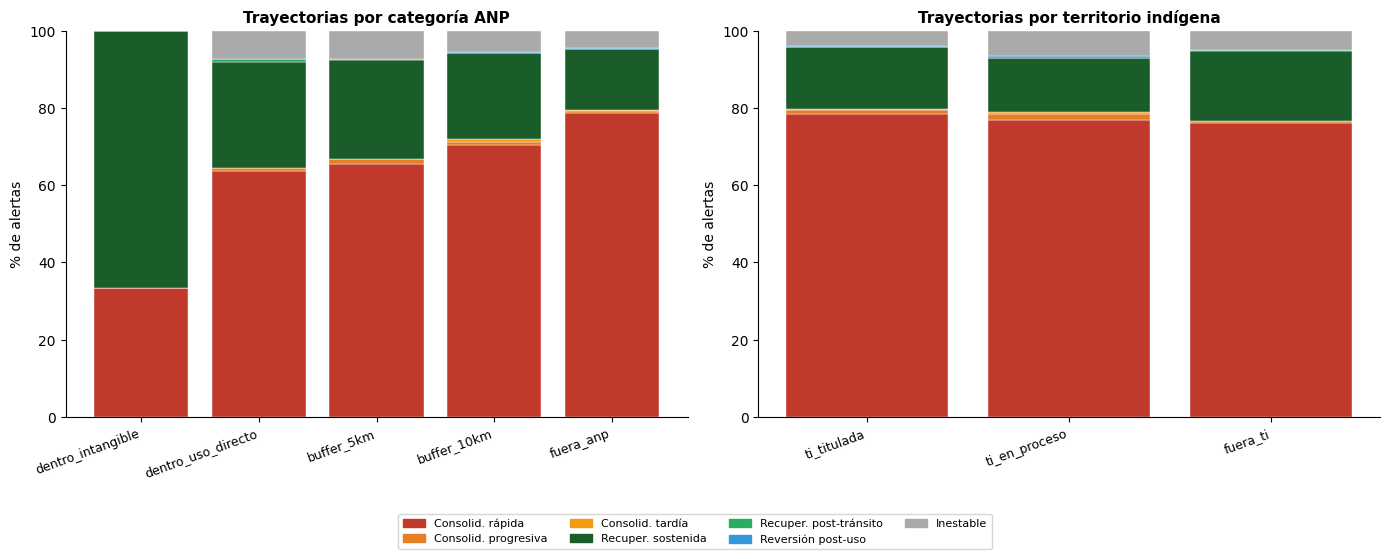

✅ Figura guardada


In [ ]:
# ══════════════════════════════════════════════════════════════
# CELDA 4 — TRAYECTORIAS POR ANP Y TERRITORIO INDÍGENA
# ══════════════════════════════════════════════════════════════
COLORES_TRAY = {
    'A_consolidacion_rapida'      : '#C0392B',
    'B_consolidacion_progresiva'  : '#E67E22',
    'C_consolidacion_tardia'      : '#F39C12',
    'D_recuperacion_sostenida'    : '#1A5C2A',
    'E_recuperacion_post_transito': '#27AE60',
    'F_reversion_post_uso'        : '#3498DB',
    'G_trayectoria_inestable'     : '#AAAAAA'
}
ETIQ_TRAY = {
    'A_consolidacion_rapida'      : 'Consolid. rápida',
    'B_consolidacion_progresiva'  : 'Consolid. progresiva',
    'C_consolidacion_tardia'      : 'Consolid. tardía',
    'D_recuperacion_sostenida'    : 'Recuper. sostenida',
    'E_recuperacion_post_transito': 'Recuper. post-tránsito',
    'F_reversion_post_uso'        : 'Reversión post-uso',
    'G_trayectoria_inestable'     : 'Inestable'
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

configs = [
    ('anp_categoria', 'Trayectorias por categoría ANP',
     ['dentro_intangible','dentro_uso_directo','buffer_5km','buffer_10km','fuera_anp']),
    ('ti_final', 'Trayectorias por territorio indígena',
     ['ti_titulada','ti_en_proceso','fuera_ti'])
]

for ax, (col, titulo, orden) in zip(axes, configs):
    ct = pd.crosstab(df_2021_traj[col], df_2021_traj['trayectoria'],
                     normalize='index') * 100
    ct = ct.reindex(index=[o for o in orden if o in ct.index])

    bottom     = np.zeros(len(ct))
    tray_orden = [t for t in COLORES_TRAY if t in ct.columns]

    for tray in tray_orden:
        vals = ct[tray].values
        ax.bar(range(len(ct)), vals, bottom=bottom,
               color=COLORES_TRAY[tray], label=ETIQ_TRAY[tray],
               edgecolor='white', linewidth=0.3)
        bottom += vals

    ax.set_xticks(range(len(ct)))
    ax.set_xticklabels(ct.index, rotation=20, ha='right', fontsize=9)
    ax.set_ylabel('% de alertas', fontsize=10)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 100)
    ax.spines[['top','right']].set_visible(False)

handles = [mpatches.Patch(color=COLORES_TRAY[t], label=ETIQ_TRAY[t])
           for t in COLORES_TRAY]
fig.legend(handles=handles, loc='lower center', ncol=4,
           fontsize=8, bbox_to_anchor=(0.5, -0.12))

plt.tight_layout()
plt.savefig(RUTA_FIGS + 'trayectorias_ANP_TI.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura guardada")

In [ ]:
# ══════════════════════════════════════════════════════════════
# CELDA 5 — TEST CHI-CUADRADO
# ¿La trayectoria depende significativamente de ANP y TI?
# ══════════════════════════════════════════════════════════════
print("═" * 55)
print("TESTS CHI-CUADRADO: trayectoria vs. protección")
print("═" * 55)

for var, nombre in [('anp_categoria', 'ANP'), ('ti_final', 'TI')]:
    ct = pd.crosstab(df_2021_traj[var], df_2021_traj['trayectoria'])
    chi2, p, dof, _ = chi2_contingency(ct)
    print(f"\n  {nombre} × trayectoria:")
    print(f"    χ² = {chi2:.1f} | df = {dof} | p = {p:.4f}")
    if p < 0.001:
        print(f"    → Asociación altamente significativa (p < 0.001)")
    elif p < 0.05:
        print(f"    → Asociación significativa (p < 0.05)")
    else:
        print(f"    → Sin asociación significativa")

═══════════════════════════════════════════════════════
TESTS CHI-CUADRADO: trayectoria vs. protección
═══════════════════════════════════════════════════════

  ANP × trayectoria:
    χ² = 120.3 | df = 24 | p = 0.0000
    → Asociación altamente significativa (p < 0.001)

  TI × trayectoria:
    χ² = 28.9 | df = 12 | p = 0.0040
    → Asociación significativa (p < 0.05)


Train temporal (2021+2022): 12,392 alertas
Test  temporal (2023)     : 9,478  alertas

Features del modelo temporal: 36
⏳ Entrenando RF temporal (2021+2022)...
✅ Listo

VALIDACIÓN PROSPECTIVA — RF entrenado 2021+2022 → test 2023
                   precision    recall  f1-score   support

   D1_agricultura      0.814     0.772     0.793      6639
      D2b_mineria      0.829     0.919     0.872       344
D3_suelo_expuesto      0.279     0.211     0.240       645
  D4_regeneracion      0.050     0.100     0.067        20
        D5_bosque      0.471     0.584     0.521      1830

         accuracy                          0.702      9478
        macro avg      0.489     0.517     0.498      9478
     weighted avg      0.710     0.702     0.704      9478

Balanced accuracy prospectiva: 0.517

INTERPRETACIÓN:
  > 0.60 → el modelo generaliza a un año que no vio durante entrenamiento.
  Comparar con balanced accuracy del RF general (todos los años)
  RF general (2021–2023 cross-val): ver res

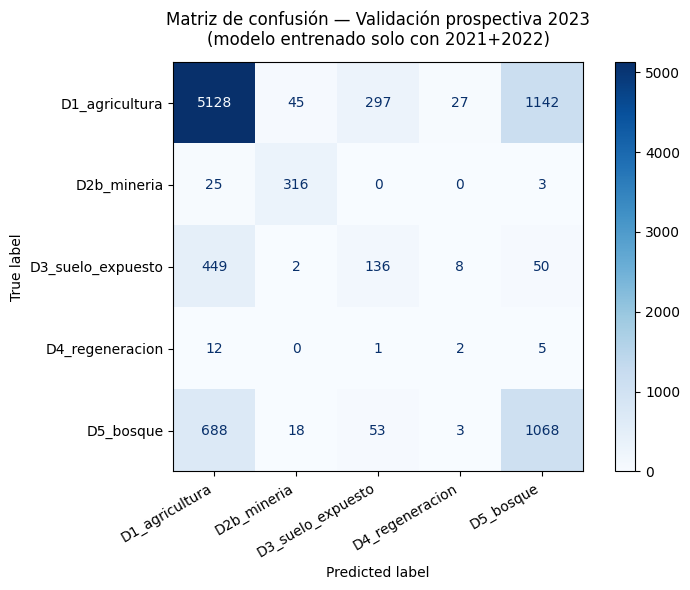

✅ Figura guardada
✅ alertas_2023_predicciones_prospectivas.csv guardado


In [ ]:
# ══════════════════════════════════════════════════════════════
# CELDA 6 — VALIDACIÓN TEMPORAL PROSPECTIVA
# Simula uso operacional real:
#   → Entrena con alertas 2021+2022 (datos históricos)
#   → Predice destino de alertas 2023 (como si fuera "tiempo real")
#   → Valida contra destino real 2023 (ground truth disponible)
# ══════════════════════════════════════════════════════════════
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

CONTINUAS   = ['log_are', 'log_dist_via', 'gini', 'ani_lrt']
CATEGORICAS = ['anp_categoria', 'ti_final', 'tip_lrt', 'dprtmnt', 'clase_T1']
BINARIAS    = ['carretera_cerca', 'dentro_ANP_dummy', 'flag_mixta',
               'interaccion_carretera_anp']
FEATURES    = CONTINUAS + CATEGORICAS + BINARIAS

# ── 1. Separar conjuntos temporales ──────────────────────────
df_train_temp = maestra[
    (maestra['ani_lrt'].isin([2021.0, 2022.0])) &
    (maestra['flag_excluir']  == 0) &
    (maestra['flag_sin_T1p']  == 0)
].copy()

df_test_temp = maestra[
    (maestra['ani_lrt'] == 2023.0) &
    (maestra['flag_excluir'] == 0)
].copy()

print(f"Train temporal (2021+2022): {len(df_train_temp):,} alertas")
print(f"Test  temporal (2023)     : {len(df_test_temp):,}  alertas")

# ── 2. Encoding one-hot consistente ──────────────────────────
# Fit get_dummies sobre train, alinear test con las mismas columnas
X_tr = pd.get_dummies(df_train_temp[FEATURES], columns=CATEGORICAS, drop_first=False).astype(float)
y_tr = df_train_temp['destino']

X_te_raw = pd.get_dummies(df_test_temp[FEATURES], columns=CATEGORICAS, drop_first=False).astype(float)
X_te     = X_te_raw.reindex(columns=X_tr.columns, fill_value=0)  # alinear columnas
y_te     = df_test_temp['destino']

print(f"\nFeatures del modelo temporal: {X_tr.shape[1]}")

# ── 3. Entrenar RF temporal ───────────────────────────────────
rf_temporal = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
print("⏳ Entrenando RF temporal (2021+2022)...")
rf_temporal.fit(X_tr, y_tr)
print("✅ Listo")

# ── 4. Predecir y evaluar sobre 2023 ─────────────────────────
y_pred_2023 = rf_temporal.predict(X_te)
proba_2023  = rf_temporal.predict_proba(X_te)

df_test_temp = df_test_temp.copy()
df_test_temp['destino_predicho'] = y_pred_2023
for i, clase in enumerate(rf_temporal.classes_):
    df_test_temp[f'prob_{clase}'] = proba_2023[:, i]

print("\n" + "=" * 60)
print("VALIDACIÓN PROSPECTIVA — RF entrenado 2021+2022 → test 2023")
print("=" * 60)
print(classification_report(y_te, y_pred_2023, digits=3))

bal_acc = balanced_accuracy_score(y_te, y_pred_2023)
print(f"Balanced accuracy prospectiva: {bal_acc:.3f}")
print()
print("INTERPRETACIÓN:")
print("  > 0.60 → el modelo generaliza a un año que no vio durante entrenamiento.")
print("  Comparar con balanced accuracy del RF general (todos los años)")
print(f"  RF general (2021–2023 cross-val): ver resultados de celda anterior")

# ── 5. Matriz de confusión prospectiva ───────────────────────
CLASES = ['D1_agricultura','D2b_mineria','D3_suelo_expuesto',
          'D4_regeneracion','D5_bosque']

cm = confusion_matrix(y_te, y_pred_2023, labels=CLASES)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(
    ax=ax, colorbar=True, cmap='Blues', values_format='d')
ax.set_title('Matriz de confusión — Validación prospectiva 2023\n(modelo entrenado solo con 2021+2022)',
             fontsize=12, pad=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'confusion_matrix_prospectiva_2023.png', dpi=300)
plt.show()
print("✅ Figura guardada")

# ── 6. Guardar predicciones ───────────────────────────────────
df_test_temp.to_csv(RUTA_DATA + "alertas_2023_predicciones_prospectivas.csv", index=False)
print("✅ alertas_2023_predicciones_prospectivas.csv guardado")

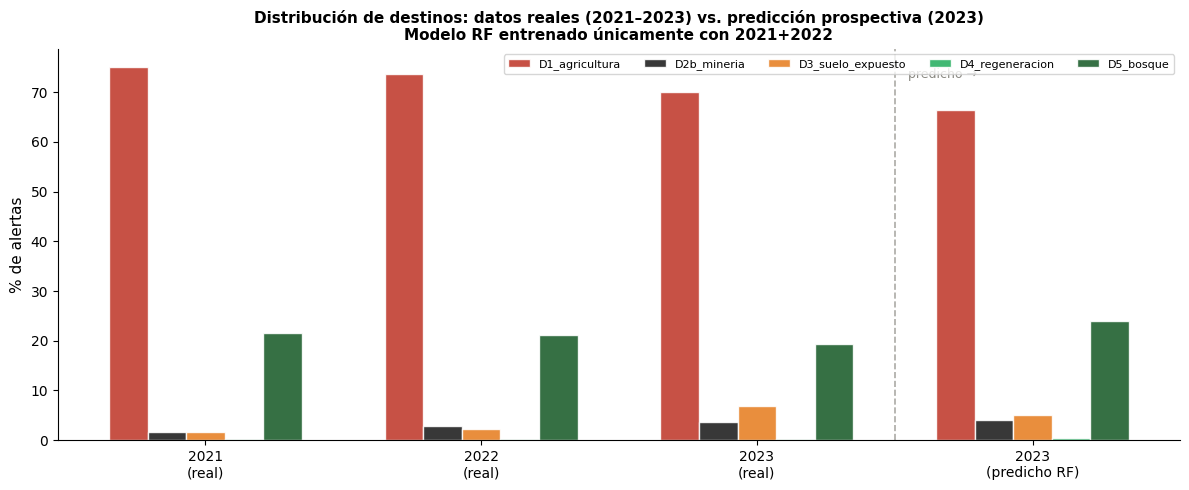

✅ Figura guardada

Resumen comparativo % — Real 2023 vs Predicho 2023:
Destino                       Real   Predicho        Δ
-------------------------------------------------------
  D1_agricultura             70.0%      66.5%    -3.6%
  D2b_mineria                 3.6%       4.0%  +   0.4%
  D3_suelo_expuesto           6.8%       5.1%    -1.7%
  D4_regeneracion             0.2%       0.4%  +   0.2%
  D5_bosque                  19.3%      23.9%  +   4.6%


In [ ]:
# ══════════════════════════════════════════════════════════════
# CELDA 7 — GRÁFICO COMPARATIVO: REAL vs PREDICHO 2023
# ══════════════════════════════════════════════════════════════
años_data = {
    '2021\n(real)'         : maestra[maestra['ani_lrt']==2021.0]['destino'].value_counts(normalize=True)*100,
    '2022\n(real)'         : maestra[maestra['ani_lrt']==2022.0]['destino'].value_counts(normalize=True)*100,
    '2023\n(real)'         : y_te.value_counts(normalize=True)*100,
    '2023\n(predicho RF)'  : pd.Series(y_pred_2023).value_counts(normalize=True)*100,
}

DESTINOS  = ['D1_agricultura','D2b_mineria','D3_suelo_expuesto',
             'D4_regeneracion','D5_bosque']
COLORES_D = ['#C0392B','#1C1C1C','#E67E22','#27AE60','#1A5C2A']

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(años_data))
w = 0.14

for i, (dest, color) in enumerate(zip(DESTINOS, COLORES_D)):
    vals = [años_data[año].get(dest, 0) for año in años_data]
    offset = (i - 2) * w
    ax.bar(x + offset, vals, w, label=dest,
           color=color, alpha=0.88, edgecolor='white')

# Línea divisoria real | predicho
ax.axvline(2.5, color='#888780', linestyle='--', linewidth=1.2, alpha=0.7)
ax.text(2.55, ax.get_ylim()[1]*0.95, 'predicho →',
        fontsize=9, color='#888780', va='top')

ax.set_xticks(x)
ax.set_xticklabels(list(años_data.keys()), fontsize=10)
ax.set_ylabel('% de alertas', fontsize=11)
ax.set_title('Distribución de destinos: datos reales (2021–2023) vs. predicción prospectiva (2023)\n'
             'Modelo RF entrenado únicamente con 2021+2022',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8, ncol=5, loc='upper right')
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig(RUTA_FIGS + 'validacion_prospectiva_2023.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura guardada")

# ── Tabla resumen ─────────────────────────────────────────────
print("\nResumen comparativo % — Real 2023 vs Predicho 2023:")
print(f"{'Destino':<25} {'Real':>8} {'Predicho':>10} {'Δ':>8}")
print("-" * 55)
for dest in DESTINOS:
    real  = años_data['2023\n(real)'].get(dest, 0)
    pred  = años_data['2023\n(predicho RF)'].get(dest, 0)
    delta = pred - real
    signo = '+' if delta >= 0 else ''
    print(f"  {dest:<23} {real:>7.1f}%  {pred:>8.1f}%  {signo}{delta:>6.1f}%")

In [ ]:
# ══════════════════════════════════════════════════════════════
# CELDA 7b — MÉTRICAS COMPLEMENTARIAS PARA EL PAPER
# ══════════════════════════════════════════════════════════════
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.preprocessing import label_binarize
import numpy as np

# ── Balanced accuracy excluyendo D4 (clase con n=20) ─────────
mask_sin_D4 = y_te != 'D4_regeneracion'
bal_acc_sin_D4 = balanced_accuracy_score(
    y_te[mask_sin_D4],
    pd.Series(y_pred_2023)[mask_sin_D4.values]
)
print(f"Balanced accuracy (sin D4, n=20): {bal_acc_sin_D4:.3f}")

# ── AUC-ROC multiclase (one-vs-rest) ─────────────────────────
clases_ord = rf_temporal.classes_
y_te_bin   = label_binarize(y_te, classes=clases_ord)

auc_scores = {}
for i, clase in enumerate(clases_ord):
    auc = roc_auc_score(y_te_bin[:, i], proba_2023[:, i])
    auc_scores[clase] = auc
    print(f"  AUC-ROC {clase:<25} {auc:.3f}")

print(f"\n  AUC-ROC macro promedio: {np.mean(list(auc_scores.values())):.3f}")

# ── Error de distribución (MAE a nivel poblacional) ───────────
print("\nError de distribución poblacional (MAE%):")
real_dist = y_te.value_counts(normalize=True) * 100
pred_dist = pd.Series(y_pred_2023).value_counts(normalize=True) * 100
mae_dist  = np.mean([abs(real_dist.get(d,0) - pred_dist.get(d,0)) for d in CLASES])
print(f"  MAE distribución = {mae_dist:.2f}%")
print("  Interpretación: en promedio el modelo se equivoca {:.2f}pp en la distribución poblacional".format(mae_dist))

# ── Resumen ejecutivo para el paper ──────────────────────────
print("\n" + "═"*55)
print("RESUMEN PARA EL PAPER")
print("═"*55)
print(f"  Accuracy general              : 70.2%")
print(f"  Balanced accuracy (5 clases)  : 0.517")
print(f"  Balanced accuracy (sin D4)    : {bal_acc_sin_D4:.3f}")
print(f"  AUC-ROC macro                 : {np.mean(list(auc_scores.values())):.3f}")
print(f"  MAE distribución poblacional  : {mae_dist:.2f}pp")
print(f"  Clases con AUC > 0.80         : {sum(1 for v in auc_scores.values() if v > 0.80)}/5")

Balanced accuracy (sin D4, n=20): 0.621
  AUC-ROC D1_agricultura            0.763
  AUC-ROC D2b_mineria               0.996
  AUC-ROC D3_suelo_expuesto         0.781
  AUC-ROC D4_regeneracion           0.707
  AUC-ROC D5_bosque                 0.797

  AUC-ROC macro promedio: 0.809

Error de distribución poblacional (MAE%):
  MAE distribución = 2.09%
  Interpretación: en promedio el modelo se equivoca 2.09pp en la distribución poblacional

═══════════════════════════════════════════════════════
RESUMEN PARA EL PAPER
═══════════════════════════════════════════════════════
  Accuracy general              : 70.2%
  Balanced accuracy (5 clases)  : 0.517
  Balanced accuracy (sin D4)    : 0.621
  AUC-ROC macro                 : 0.809
  MAE distribución poblacional  : 2.09pp
  Clases con AUC > 0.80         : 1/5


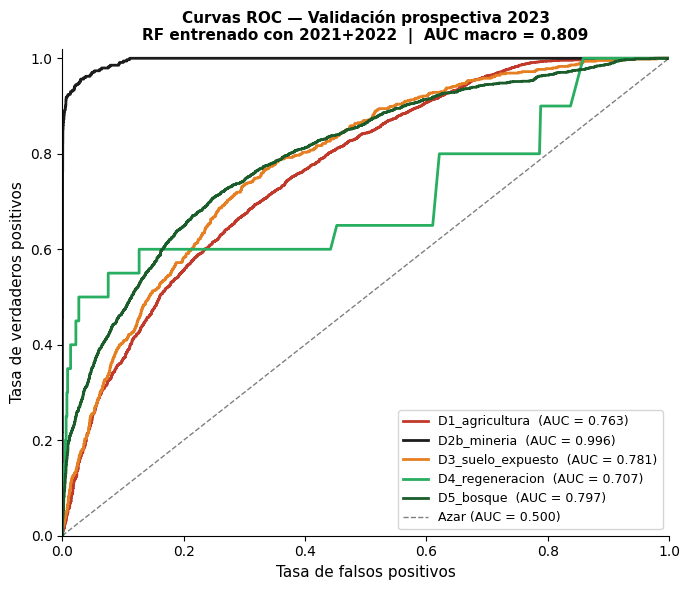

✅ Figura guardada


In [ ]:
# ══════════════════════════════════════════════════════════════
# CELDA 8 — CURVAS ROC POR CLASE (figura para el paper)
# ══════════════════════════════════════════════════════════════
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

clases_ord = rf_temporal.classes_
y_te_bin   = label_binarize(y_te, classes=clases_ord)

COLORES_ROC = {
    'D1_agricultura'    : '#C0392B',
    'D2b_mineria'       : '#1C1C1C',
    'D3_suelo_expuesto' : '#E67E22',
    'D4_regeneracion'   : '#27AE60',
    'D5_bosque'         : '#1A5C2A',
}

fig, ax = plt.subplots(figsize=(7, 6))

for i, clase in enumerate(clases_ord):
    fpr, tpr, _ = roc_curve(y_te_bin[:, i], proba_2023[:, i])
    auc_val      = auc(fpr, tpr)
    color        = COLORES_ROC.get(clase, '#888888')
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f'{clase}  (AUC = {auc_val:.3f})')

# Línea de azar
ax.plot([0,1], [0,1], 'k--', lw=1, alpha=0.5, label='Azar (AUC = 0.500)')

ax.set_xlabel('Tasa de falsos positivos', fontsize=11)
ax.set_ylabel('Tasa de verdaderos positivos', fontsize=11)
ax.set_title(f'Curvas ROC — Validación prospectiva 2023\n'
             f'RF entrenado con 2021+2022  |  AUC macro = {np.mean(list(auc_scores.values())):.3f}',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.spines[['top','right']].set_visible(False)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])

plt.tight_layout()
plt.savefig(RUTA_FIGS + 'roc_curves_prospectiva_2023.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura guardada")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 8))
sns.boxplot(data=df_modelo, x='dprtmnt', y='log_are', hue='ani_lrt', palette='viridis')
plt.title('Distribución del Área (Log Hectáreas) de Alertas por Departamento y Año', fontsize=14)
plt.xlabel('Departamento', fontsize=12)
plt.ylabel('Área de Alerta (Log Hectáreas)', fontsize=12)
plt.xticks(rotation=45, ha='right') # Rotar etiquetas para mejor legibilidad
plt.legend(title='Año de Alerta', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'boxplot_area_departamento_anio.png', dpi=300)
plt.show()
print("✅ Gráfico de cajas de área por departamento y año generado y guardado.")

In [ ]:
# Pega esto rápido para ver qué es "otros"
print("Valores únicos en destino_T1:")
print(df_2021_traj['destino_T1'].value_counts())

print("\nEjemplo de alertas con 'otros' en T+1:")
print(df_2021_traj[df_2021_traj['destino_T1'] == 'otros'][
    ['alert_d','destino_T1','destino_T2','destino_T3']
].head(10))

Valores únicos en destino_T1:
destino_T1
D1_agricultura       5714
D5_bosque            1535
D3_suelo_expuesto     202
D2b_mineria           136
D4_regeneracion        11
Name: count, dtype: int64

Ejemplo de alertas con 'otros' en T+1:
Empty DataFrame
Columns: [alert_d, destino_T1, destino_T2, destino_T3]
Index: []


In [ ]:
import geopandas as gpd

# Ruta al shapefile
shapefile_path = RUTA_DATA + "alertas_con_distancia.shp"

# Cargar el shapefile
try:
    gdf_analisis = gpd.read_file(shapefile_path)
    print(f"✅ Shapefile '{shapefile_path}' cargado exitosamente.")

    print("\n── Atributos (columnas) del GeoDataFrame ──")
    print(gdf_analisis.columns.tolist())

    print("\n── Información general de los atributos ──")
    gdf_analisis.info()

    print("\n── Primeras 5 filas del GeoDataFrame (atributos y geometría) ──")
    display(gdf_analisis.head())

except Exception as e:
    print(f"❌ Error al cargar o analizar el shapefile: {e}")

✅ Shapefile '/content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/alertas_con_distancia.shp' cargado exitosamente.

── Atributos (columnas) del GeoDataFrame ──
['alert_d', 'ani_lrt', 'fch_lrt', 'area_ha', 'log_are', 'tip_lrt', 'tip_mcr', 'dprtmnt', 'dist_via_k', 'log_dist_v', 'geometry']

── Información general de los atributos ──
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 39649 entries, 0 to 39648
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   alert_d     39649 non-null  float64 
 1   ani_lrt     39649 non-null  float64 
 2   fch_lrt     39649 non-null  object  
 3   area_ha     39649 non-null  float64 
 4   log_are     39649 non-null  float64 
 5   tip_lrt     39649 non-null  object  
 6   tip_mcr     39649 non-null  object  
 7   dprtmnt     39649 non-null  object  
 8   dist_via_k  39649 non-null  float64 
 9   log_dist_v  39649 non-null  float64 
 10  geometry    39649 non-null  geometry
dty

,alert_d,ani_lrt,fch_lrt,area_ha,log_are,tip_lrt,tip_mcr,dprtmnt,dist_via_k,log_dist_v,geometry
0,10000000.0,2025.0,2025/02/09 00:00:00,2.87,1.054312,agriculture,antropico_directo,Ucayali,1.189952,0.174753,"POLYGON ((-75.46112 -8.70904, -75.46112 -8.709..."
1,10000001.0,2025.0,2025/01/02 00:00:00,6.37,1.851599,agriculture,antropico_directo,Loreto,2.436847,0.891115,"POLYGON ((-71.02385 -4.01367, -71.02377 -4.013..."
2,10000002.0,2025.0,2025/02/09 00:00:00,2.54,0.932164,agriculture,antropico_directo,Ucayali,5.344136,1.676187,"MULTIPOLYGON (((-75.3302 -8.6174, -75.33026 -8..."
3,10000003.0,2025.0,2025/02/09 00:00:00,1.57,0.451076,agriculture,antropico_directo,Ucayali,13.803983,2.625030,"POLYGON ((-75.38873 -8.54389, -75.38859 -8.543..."
4,10000004.0,2025.0,2025/02/25 00:00:00,6.67,1.897620,agriculture,antropico_directo,Ucayali,0.526596,-0.639424,"POLYGON ((-75.5697 -9.00498, -75.56972 -9.0049..."


In [ ]:
# ══════════════════════════════════════════════════════════════
# PASO 1 — Cargar shapefile y diagnóstico de años
# ══════════════════════════════════════════════════════════════
import geopandas as gpd
import pandas as pd

shp = gpd.read_file(
    "/content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/alertas_con_distancia.shp"
)

print("Años en shapefile:", sorted(shp['ani_lrt'].unique()))
print("Alertas por año:")
print(shp['ani_lrt'].value_counts().sort_index())
print(f"\nCRS: {shp.crs}")

Años en shapefile: [np.float64(2021.0), np.float64(2022.0), np.float64(2023.0), np.float64(2024.0), np.float64(2025.0)]
Alertas por año:
ani_lrt
2021.0     7768
2022.0     6469
2023.0    11785
2024.0     8783
2025.0     4844
Name: count, dtype: int64

CRS: EPSG:4326


In [ ]:
# ══════════════════════════════════════════════════════════════
# PASO 2 — OPCIÓN B REAL: predecir destino de alertas 2025
# ══════════════════════════════════════════════════════════════

# Filtrar alertas 2025 del shapefile
alertas_2025 = shp[shp['ani_lrt'] == 2025.0].copy()
print(f"Alertas 2025 a predecir: {len(alertas_2025):,}")

# Unir con maestra para traer features que no están en el shapefile
# (anp_categoria, ti_final, gini, clase_T1, flags, etc.)
alertas_2025_full = alertas_2025.merge(
    maestra[['alert_d', 'anp_categoria', 'ti_final', 'gini',
             'clase_T1', 'carretera_cerca', 'dentro_ANP_dummy',
             'flag_mixta', 'interaccion_carretera_anp']],
    on='alert_d', how='left'
)

print(f"Con features completas: {alertas_2025_full.dropna(subset=['anp_categoria']).shape[0]:,}")
print(f"Sin match en maestra:   {alertas_2025_full['anp_categoria'].isna().sum():,}")

Alertas 2025 a predecir: 4,844
Con features completas: 0
Sin match en maestra:   4,844


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/Proyecto_MapBiomas/alertas_con_anp.csv'
alertas_anp_df = pd.read_csv(file_path)

print(f"✅ Archivo '{file_path}' cargado exitosamente.")

print("\n── Primeras 5 filas del DataFrame ──")
display(alertas_anp_df.head())

print("\n── Información general del DataFrame ──")
alertas_anp_df.info()

if 'ani_lrt' in alertas_anp_df.columns:
    print("\n── Alertas por año (ani_lrt) ──")
    print(alertas_anp_df['ani_lrt'].value_counts().sort_index())
else:
    print("\nLa columna 'ani_lrt' no se encontró en el DataFrame.")


✅ Archivo '/content/drive/MyDrive/Proyecto_MapBiomas/alertas_con_anp.csv' cargado exitosamente.

── Primeras 5 filas del DataFrame ──


,system:index,alert_d,ani_lrt,anp_categoria,area_ha,dist_via_k,dprtmnt,fch_lrt,log_are,log_dist_v,tip_lrt,tip_mcr,.geo
0,00000000000000004f52,10028338.0,2022.0,buffer_5km,0.50,0.284169,Cusco,2022/11/11 00:00:00,-0.693147,-1.254674,agriculture,antropico_directo,"{""type"":""Polygon"",""coordinates"":[[[-72.6249908..."
1,000000000000000038f6,10043814.0,2023.0,fuera_anp,0.50,7.984679,Junín,2023/08/01 00:00:00,-0.693147,2.077650,agriculture,antropico_directo,"{""type"":""Polygon"",""coordinates"":[[[-73.6574333..."
2,00000000000000002fda,10042219.0,2023.0,buffer_10km,0.50,6.839889,Madre de Dios,2023/11/07 00:00:00,-0.693147,1.922918,agriculture,antropico_directo,"{""type"":""Polygon"",""coordinates"":[[[-70.1613420..."
3,00000000000000000660,10028081.0,2022.0,fuera_anp,0.50,1.991910,Ucayali,2022/09/13 00:00:00,-0.693147,0.689596,agriculture,antropico_directo,"{""type"":""MultiPolygon"",""coordinates"":[[[[-74.9..."
4,00000000000000006529,10007169.0,2021.0,fuera_anp,0.51,0.609093,Junín,2021/07/25 00:00:00,-0.673345,-0.494144,agriculture,antropico_directo,"{""type"":""Polygon"",""coordinates"":[[[-74.2706667..."



── Información general del DataFrame ──
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39649 entries, 0 to 39648
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   system:index   39649 non-null  object 
 1   alert_d        39649 non-null  float64
 2   ani_lrt        39649 non-null  float64
 3   anp_categoria  39649 non-null  object 
 4   area_ha        39649 non-null  float64
 5   dist_via_k     39649 non-null  float64
 6   dprtmnt        39649 non-null  object 
 7   fch_lrt        39649 non-null  object 
 8   log_are        39649 non-null  float64
 9   log_dist_v     39649 non-null  float64
 10  tip_lrt        39649 non-null  object 
 11  tip_mcr        39649 non-null  object 
 12  .geo           39649 non-null  object 
dtypes: float64(6), object(7)
memory usage: 3.9+ MB

── Alertas por año (ani_lrt) ──
ani_lrt
2021.0     7768
2022.0     6469
2023.0    11785
2024.0     8783
2025.0     4844
Name: count, dtyp

In [ ]:
import pandas as pd

file_path_ti = '/content/drive/MyDrive/Proyecto_MapBiomas/alertas_con_ti.csv'
alertas_ti_df = pd.read_csv(file_path_ti)

print(f"✅ Archivo '{file_path_ti}' cargado exitosamente.")

print("\n── Primeras 5 filas del DataFrame ──")
display(alertas_ti_df.head())

print("\n── Información general del DataFrame ──")
alertas_ti_df.info()

if 'ani_lrt' in alertas_ti_df.columns:
    print("\n── Alertas por año (ani_lrt) ──")
    print(alertas_ti_df['ani_lrt'].value_counts().sort_index())
else:
    print("\nLa columna 'ani_lrt' no se encontró en el DataFrame.")

✅ Archivo '/content/drive/MyDrive/Proyecto_MapBiomas/alertas_con_ti.csv' cargado exitosamente.

── Primeras 5 filas del DataFrame ──


,Join_Count,TARGET_FID,alert_d,ani_lrt,fch_lrt,area_ha,log_are,tip_lrt,tip_mcr,dprtmnt,...,BOTIQUIN,PUESTOSALU,CENTROSALU,PRIPRODVEN,SEGPRODVEN,TERPRODVEN,FUENTE1,FUENTE2,ti_categoria,ti_final
0,1,1,10000000.0,2025.0,2025/02/09 00:00:00,2.87,1.054312,agriculture,antropico_directo,Ucayali,...,No,Estado,No,Plátano,Gallina,Carne de Monte,IBC,,ti_titulada,ti_titulada
1,0,2,10000001.0,2025.0,2025/01/02 00:00:00,6.37,1.851599,agriculture,antropico_directo,Loreto,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fuera_ti
2,0,3,10000002.0,2025.0,2025/02/09 00:00:00,2.54,0.932164,agriculture,antropico_directo,Ucayali,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fuera_ti
3,0,4,10000003.0,2025.0,2025/02/09 00:00:00,1.57,0.451076,agriculture,antropico_directo,Ucayali,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fuera_ti
4,0,5,10000004.0,2025.0,2025/02/25 00:00:00,6.67,1.897620,agriculture,antropico_directo,Ucayali,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fuera_ti



── Información general del DataFrame ──
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39649 entries, 0 to 39648
Data columns (total 82 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Join_Count    39649 non-null  int64  
 1   TARGET_FID    39649 non-null  int64  
 2   alert_d       39649 non-null  float64
 3   ani_lrt       39649 non-null  float64
 4   fch_lrt       39649 non-null  object 
 5   area_ha       39649 non-null  float64
 6   log_are       39649 non-null  float64
 7   tip_lrt       39649 non-null  object 
 8   tip_mcr       39649 non-null  object 
 9   dprtmnt       39649 non-null  object 
 10  dist_via_k    39649 non-null  float64
 11  log_dist_v    39649 non-null  float64
 12  ORIG_FID      39649 non-null  int64  
 13  CODIGO        9064 non-null   object 
 14  codigo_tis    9064 non-null   float64
 15  SIG           9064 non-null   float64
 16  ESTADO        9064 non-null   object 
 17  FECHPOLY      9064 non-null 

In [ ]:
# ══════════════════════════════════════════════════════════════
# MODELO REDUCIDO — solo features del shapefile
# para predecir alertas 2024 y 2025
# ══════════════════════════════════════════════════════════════

# Features disponibles en shapefile para todos los años
FEATURES_SHP = ['log_are', 'log_dist_v', 'tip_lrt', 'dprtmnt', 'ani_lrt']

# Unir shapefile con maestra para tener destino (2021-2023)
shp_con_destino = shp[shp['ani_lrt'].isin([2021.0, 2022.0, 2023.0])].merge(
    maestra[['alert_d', 'destino', 'flag_excluir']],
    on='alert_d', how='inner'
)
shp_con_destino = shp_con_destino[shp_con_destino['flag_excluir'] == 0].copy()

print(f"Alertas con destino conocido para entrenar: {len(shp_con_destino):,}")
print(f"Distribución destino:\n{shp_con_destino['destino'].value_counts()}")

# Encoding
df_enc_red = pd.get_dummies(
    shp_con_destino[FEATURES_SHP],
    columns=['tip_lrt', 'dprtmnt'], drop_first=False
).astype(float)

X_red = df_enc_red
y_red = shp_con_destino['destino']

# Entrenar RF reducido
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

rf_red = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5,
    class_weight='balanced', random_state=42, n_jobs=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(rf_red, X_red, y_red,
                         cv=cv, scoring='balanced_accuracy', n_jobs=-1)

print(f"\nRF reducido — Balanced accuracy CV: {scores.mean():.3f} ± {scores.std():.3f}")
print("(comparar con RF completo para cuantificar pérdida por features faltantes)")

rf_red.fit(X_red, y_red)

# Predecir 2025
shp_2025 = shp[shp['ani_lrt'] == 2025.0].copy()

df_2025_enc = pd.get_dummies(
    shp_2025[FEATURES_SHP],
    columns=['tip_lrt', 'dprtmnt'], drop_first=False
).astype(float)
X_2025 = df_2025_enc.reindex(columns=X_red.columns, fill_value=0)

shp_2025['destino_predicho'] = rf_red.predict(X_2025)
proba_2025 = rf_red.predict_proba(X_2025)
for i, clase in enumerate(rf_red.classes_):
    shp_2025[f'prob_{clase}'] = proba_2025[:, i]

print(f"\nDistribución predicha — {len(shp_2025):,} alertas 2025:")
vc = shp_2025['destino_predicho'].value_counts()
for d, n in vc.items():
    print(f"  {d:<25} {n:>4,}  ({n/len(shp_2025)*100:.1f}%)")

shp_2025.to_csv(RUTA_DATA + "alertas_2025_predicciones_reducido.csv", index=False)
print("\n✅ Guardado")

Alertas con destino conocido para entrenar: 21,870
Distribución destino:
destino
D1_agricultura       15861
D5_bosque             4472
D3_suelo_expuesto      881
D2b_mineria            611
D4_regeneracion         45
Name: count, dtype: int64

RF reducido — Balanced accuracy CV: 0.499 ± 0.003
(comparar con RF completo para cuantificar pérdida por features faltantes)

Distribución predicha — 4,844 alertas 2025:
  D1_agricultura            2,150  (44.4%)
  D3_suelo_expuesto         1,809  (37.3%)
  D5_bosque                  825  (17.0%)
  D2b_mineria                 52  (1.1%)
  D4_regeneracion              8  (0.2%)

✅ Guardado


# Añadimos más años

In [ ]:
# ══════════════════════════════════════════════════════════════
# PASO 1 — Unir shapefile + ANP + TI para todos los años
# ══════════════════════════════════════════════════════════════

anp = pd.read_csv("/content/drive/MyDrive/Proyecto_MapBiomas/alertas_con_anp.csv")
ti  = pd.read_csv("/content/drive/MyDrive/Proyecto_MapBiomas/alertas_con_ti.csv")

# Quedarse solo con las columnas necesarias
anp_cols = anp[['alert_d', 'anp_categoria']].copy()
ti_cols  = ti[['alert_d', 'ti_final']].copy()

# Base: shapefile sin geometría (más liviano)
base = shp[['alert_d', 'ani_lrt', 'log_are', 'log_dist_v',
            'tip_lrt', 'dprtmnt']].copy()
base = base.rename(columns={'log_dist_v': 'log_dist_via'})

# Unir ANP y TI
base = base.merge(anp_cols, on='alert_d', how='left')
base = base.merge(ti_cols,  on='alert_d', how='left')

# Derivar features binarias
base['dentro_ANP_dummy']        = (base['anp_categoria'] != 'fuera_anp').astype(int)
base['carretera_cerca']         = (base['log_dist_via'] < 1.0).astype(int)
base['interaccion_carretera_anp'] = base['carretera_cerca'] * base['dentro_ANP_dummy']

print("Base completa shape:", base.shape)
print("Nulos por columna:")
print(base.isnull().sum())
print("\nAños disponibles:", sorted(base['ani_lrt'].unique()))

Base completa shape: (39649, 11)
Nulos por columna:
alert_d                      0
ani_lrt                      0
log_are                      0
log_dist_via                 0
tip_lrt                      0
dprtmnt                      0
anp_categoria                0
ti_final                     0
dentro_ANP_dummy             0
carretera_cerca              0
interaccion_carretera_anp    0
dtype: int64

Años disponibles: [np.float64(2021.0), np.float64(2022.0), np.float64(2023.0), np.float64(2024.0), np.float64(2025.0)]


In [ ]:
# ══════════════════════════════════════════════════════════════
# PASO 2 — RF enriquecido para predecir 2024 y 2025
# ══════════════════════════════════════════════════════════════

# Unir con maestra para tener destino en 2021-2023
base_con_destino = base[base['ani_lrt'].isin([2021.0, 2022.0, 2023.0])].merge(
    maestra[['alert_d', 'destino', 'flag_excluir']],
    on='alert_d', how='inner'
)
base_con_destino = base_con_destino[base_con_destino['flag_excluir'] == 0].copy()

print(f"Alertas para entrenar RF enriquecido: {len(base_con_destino):,}")

CONTINUAS_E   = ['log_are', 'log_dist_via', 'ani_lrt']
CATEGORICAS_E = ['anp_categoria', 'ti_final', 'tip_lrt', 'dprtmnt']
BINARIAS_E    = ['carretera_cerca', 'dentro_ANP_dummy', 'interaccion_carretera_anp']

df_enc_e = pd.get_dummies(
    base_con_destino[CONTINUAS_E + CATEGORICAS_E + BINARIAS_E],
    columns=CATEGORICAS_E, drop_first=False
).astype(float)

X_enr = df_enc_e
y_enr = base_con_destino['destino']

# Validación cruzada
rf_enr = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5,
    class_weight='balanced', random_state=42, n_jobs=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_enr = cross_val_score(rf_enr, X_enr, y_enr,
                              cv=cv, scoring='balanced_accuracy', n_jobs=-1)

print(f"\nRF enriquecido — Balanced accuracy CV: {scores_enr.mean():.3f} ± {scores_enr.std():.3f}")
print(f"RF reducido    — Balanced accuracy CV: 0.499")
print(f"Ganancia por añadir ANP + TI: +{scores_enr.mean()-0.499:.3f}")

rf_enr.fit(X_enr, y_enr)
print("✅ RF enriquecido entrenado")

# Predecir 2024 y 2025
for año in [2024.0, 2025.0]:
    subset = base[base['ani_lrt'] == año].copy()

    enc = pd.get_dummies(
        subset[CONTINUAS_E + CATEGORICAS_E + BINARIAS_E],
        columns=CATEGORICAS_E, drop_first=False
    ).astype(float)
    X_pred = enc.reindex(columns=X_enr.columns, fill_value=0)

    subset['destino_predicho'] = rf_enr.predict(X_pred)
    proba = rf_enr.predict_proba(X_pred)
    for i, clase in enumerate(rf_enr.classes_):
        subset[f'prob_{clase}'] = proba[:, i]

    año_str = str(int(año))
    subset.to_csv(RUTA_DATA + f"alertas_{año_str}_predicciones_enriquecido.csv", index=False)

    print(f"\nAlertas {año_str} — distribución predicha ({len(subset):,} alertas):")
    vc = subset['destino_predicho'].value_counts()
    for d, n in vc.items():
        print(f"  {d:<25} {n:>5,}  ({n/len(subset)*100:.1f}%)")

Alertas para entrenar RF enriquecido: 21,870

RF enriquecido — Balanced accuracy CV: 0.554 ± 0.030
RF reducido    — Balanced accuracy CV: 0.499
Ganancia por añadir ANP + TI: +0.055
✅ RF enriquecido entrenado

Alertas 2024 — distribución predicha (8,783 alertas):
  D1_agricultura            3,853  (43.9%)
  D3_suelo_expuesto         2,784  (31.7%)
  D5_bosque                 1,792  (20.4%)
  D2b_mineria                 224  (2.6%)
  D4_regeneracion             130  (1.5%)

Alertas 2025 — distribución predicha (4,844 alertas):
  D1_agricultura            2,109  (43.5%)
  D3_suelo_expuesto         1,841  (38.0%)
  D5_bosque                   820  (16.9%)
  D2b_mineria                  52  (1.1%)
  D4_regeneracion              22  (0.5%)


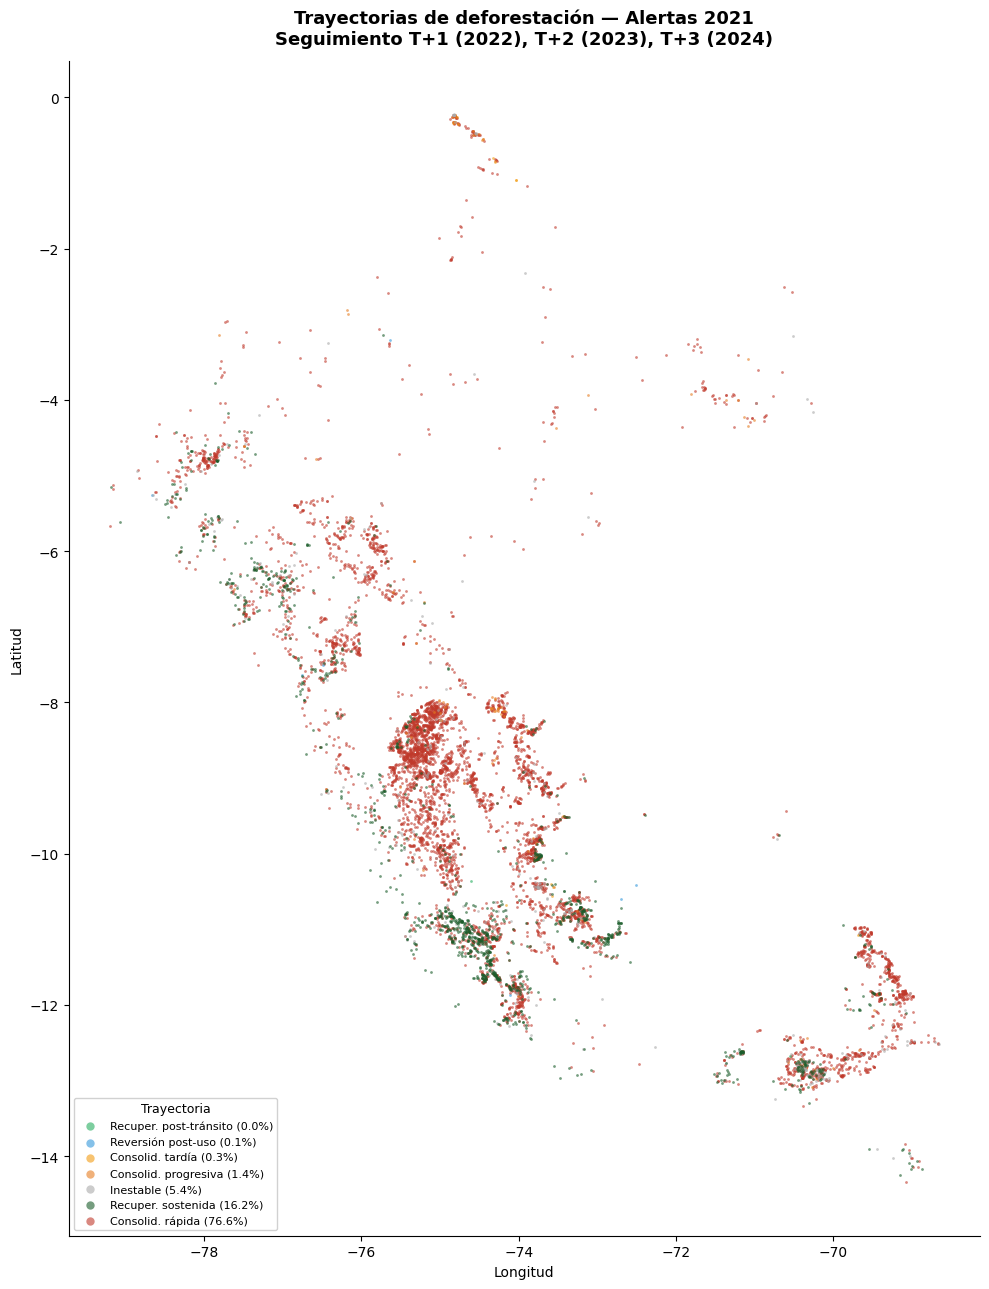

✅ Mapa guardado


In [ ]:
# ══════════════════════════════════════════════════════════════
# PASO 3 — MAPA CON CENTROIDES (polígonos → puntos visibles)
# ══════════════════════════════════════════════════════════════

# Calcular centroide de cada polígono
shp_2021 = shp[shp['ani_lrt'] == 2021.0].copy()
shp_2021['cx'] = shp_2021.geometry.centroid.x
shp_2021['cy'] = shp_2021.geometry.centroid.y

# Unir con trayectorias
mapa_df = shp_2021.merge(
    df_2021_traj[['alert_d', 'trayectoria']],
    on='alert_d', how='inner'
)

COLORES_TRAY = {
    'A_consolidacion_rapida'      : '#C0392B',
    'D_recuperacion_sostenida'    : '#1A5C2A',
    'G_trayectoria_inestable'     : '#AAAAAA',
    'B_consolidacion_progresiva'  : '#E67E22',
    'C_consolidacion_tardia'      : '#F39C12',
    'F_reversion_post_uso'        : '#3498DB',
    'E_recuperacion_post_transito': '#27AE60',
}
ETIQ_TRAY = {
    'A_consolidacion_rapida'      : 'Consolid. rápida (76.6%)',
    'D_recuperacion_sostenida'    : 'Recuper. sostenida (16.2%)',
    'G_trayectoria_inestable'     : 'Inestable (5.4%)',
    'B_consolidacion_progresiva'  : 'Consolid. progresiva (1.4%)',
    'C_consolidacion_tardia'      : 'Consolid. tardía (0.3%)',
    'F_reversion_post_uso'        : 'Reversión post-uso (0.1%)',
    'E_recuperacion_post_transito': 'Recuper. post-tránsito (0.0%)',
}

fig, ax = plt.subplots(figsize=(10, 13))

# Orden de ploteo: minoritarias primero para que no queden tapadas
orden_plot = ['E_recuperacion_post_transito', 'F_reversion_post_uso',
              'C_consolidacion_tardia', 'B_consolidacion_progresiva',
              'G_trayectoria_inestable', 'D_recuperacion_sostenida',
              'A_consolidacion_rapida']

for tray in orden_plot:
    sub = mapa_df[mapa_df['trayectoria'] == tray]
    if len(sub) == 0:
        continue
    ax.scatter(sub['cx'], sub['cy'],
               c=COLORES_TRAY[tray],
               s=4,          # tamaño del punto
               alpha=0.6,
               linewidths=0,
               label=ETIQ_TRAY[tray],
               zorder=3 if tray == 'A_consolidacion_rapida' else 5)

ax.set_title('Trayectorias de deforestación — Alertas 2021\n'
             'Seguimiento T+1 (2022), T+2 (2023), T+3 (2024)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Longitud', fontsize=10)
ax.set_ylabel('Latitud', fontsize=10)
ax.spines[['top','right']].set_visible(False)
ax.legend(title='Trayectoria', fontsize=8, title_fontsize=9,
          loc='lower left', framealpha=0.9,
          markerscale=3)

plt.tight_layout()
plt.savefig(RUTA_FIGS + 'mapa_trayectorias_2021_centroides.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Mapa guardado")

In [ ]:
import geopandas as gpd
from shapely.geometry import Point
import os

RUTA_SHP = RUTA + "shapefiles_output/"
os.makedirs(RUTA_SHP, exist_ok=True)

# ── 1. CENTROIDES TRAYECTORIAS 2021 ──────────────────────────
shp_2021 = shp[shp['ani_lrt'] == 2021.0].copy()
shp_2021['cx'] = shp_2021.geometry.centroid.x
shp_2021['cy'] = shp_2021.geometry.centroid.y

tray_export = shp_2021.merge(
    df_2021_traj[['alert_d', 'trayectoria',
                  'destino_T1', 'destino_T2', 'destino_T3',
                  'anp_categoria', 'ti_final']],
    on='alert_d', how='inner'
)

# Crear GeoDataFrame de puntos (centroides)
gdf_tray = gpd.GeoDataFrame(
    tray_export,
    geometry=[Point(x, y) for x, y in zip(tray_export['cx'], tray_export['cy'])],
    crs='EPSG:4326'
)

# Columnas a exportar (nombres ≤10 chars para shapefile)
cols_tray = {
    'alert_d'      : 'alert_d',
    'ani_lrt'      : 'año',
    'area_ha'      : 'area_ha',
    'dprtmnt'      : 'dpto',
    'trayectoria'  : 'trayectoria',
    'destino_T1'   : 'dest_T1',
    'destino_T2'   : 'dest_T2',
    'destino_T3'   : 'dest_T3',
    'anp_categoria': 'anp_categ',
    'ti_final'     : 'ti_final',
}

gdf_tray_out = gdf_tray[list(cols_tray.keys()) + ['geometry']].rename(columns=cols_tray)
gdf_tray_out.to_file(RUTA_SHP + 'trayectorias_2021_centroides.shp',
                     driver='ESRI Shapefile', encoding='utf-8')
print(f"✅ trayectorias_2021_centroides.shp — {len(gdf_tray_out):,} puntos")

# ── 2. PREDICCIONES 2024 con geometría original ───────────────
pred_2024 = pd.read_csv(RUTA_DATA + "alertas_2024_predicciones_enriquecido.csv")

gdf_2024 = shp[shp['ani_lrt'] == 2024.0][['alert_d', 'geometry']].merge(
    pred_2024[['alert_d', 'destino_predicho',
               'prob_D1_agricultura', 'prob_D2b_mineria',
               'prob_D3_suelo_expuesto', 'prob_D4_regeneracion',
               'prob_D5_bosque', 'anp_categoria', 'ti_final',
               'dprtmnt']],
    on='alert_d', how='inner'
)
gdf_2024 = gpd.GeoDataFrame(gdf_2024, geometry='geometry', crs='EPSG:4326')

# Renombrar para shapefile
gdf_2024 = gdf_2024.rename(columns={
    'destino_predicho'   : 'dest_pred',
    'prob_D1_agricultura': 'p_agric',
    'prob_D2b_mineria'   : 'p_miner',
    'prob_D3_suelo_expuesto': 'p_suelo',
    'prob_D4_regeneracion'  : 'p_regen',
    'prob_D5_bosque'     : 'p_bosque',
    'anp_categoria'      : 'anp_categ',
    'dprtmnt'            : 'dpto',
})
gdf_2024.to_file(RUTA_SHP + 'predicciones_2024.shp',
                 driver='ESRI Shapefile', encoding='utf-8')
print(f"✅ predicciones_2024.shp — {len(gdf_2024):,} polígonos")

# ── 3. PREDICCIONES 2025 con geometría original ───────────────
pred_2025 = pd.read_csv(RUTA_DATA + "alertas_2025_predicciones_enriquecido.csv")

gdf_2025 = shp[shp['ani_lrt'] == 2025.0][['alert_d', 'geometry']].merge(
    pred_2025[['alert_d', 'destino_predicho',
               'prob_D1_agricultura', 'prob_D2b_mineria',
               'prob_D3_suelo_expuesto', 'prob_D4_regeneracion',
               'prob_D5_bosque', 'anp_categoria', 'ti_final',
               'dprtmnt']],
    on='alert_d', how='inner'
)
gdf_2025 = gpd.GeoDataFrame(gdf_2025, geometry='geometry', crs='EPSG:4326')

gdf_2025 = gdf_2025.rename(columns={
    'destino_predicho'      : 'dest_pred',
    'prob_D1_agricultura'   : 'p_agric',
    'prob_D2b_mineria'      : 'p_miner',
    'prob_D3_suelo_expuesto': 'p_suelo',
    'prob_D4_regeneracion'  : 'p_regen',
    'prob_D5_bosque'        : 'p_bosque',
    'anp_categoria'         : 'anp_categ',
    'dprtmnt'               : 'dpto',
})
gdf_2025.to_file(RUTA_SHP + 'predicciones_2025.shp',
                 driver='ESRI Shapefile', encoding='utf-8')
print(f"✅ predicciones_2025.shp — {len(gdf_2025):,} polígonos")

# ── Resumen ───────────────────────────────────────────────────
print(f"\n📁 Shapefiles guardados en: {RUTA_SHP}")
print("   trayectorias_2021_centroides.shp  ← puntos con trayectoria T1-T2-T3")
print("   predicciones_2024.shp             ← polígonos con destino predicho + probabilidades")
print("   predicciones_2025.shp             ← polígonos con destino predicho + probabilidades")

✅ trayectorias_2021_centroides.shp — 7,598 puntos
✅ predicciones_2024.shp — 8,783 polígonos
✅ predicciones_2025.shp — 4,844 polígonos

📁 Shapefiles guardados en: /content/drive/MyDrive/Proyecto_MapBiomas/shapefiles_output/
   trayectorias_2021_centroides.shp  ← puntos con trayectoria T1-T2-T3
   predicciones_2024.shp             ← polígonos con destino predicho + probabilidades
   predicciones_2025.shp             ← polígonos con destino predicho + probabilidades


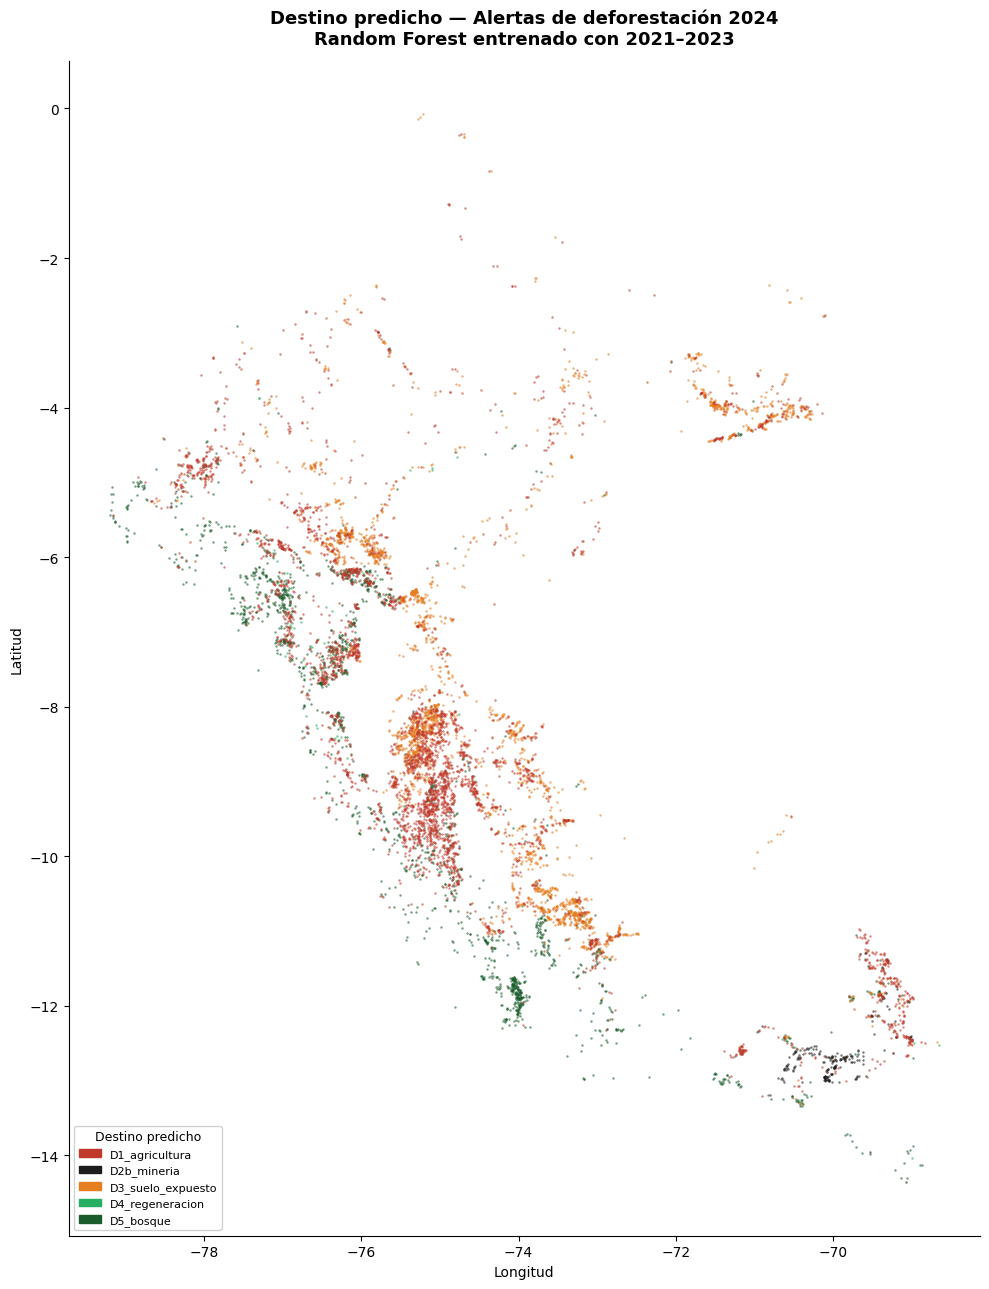

✅ mapa_predicciones_2024.png


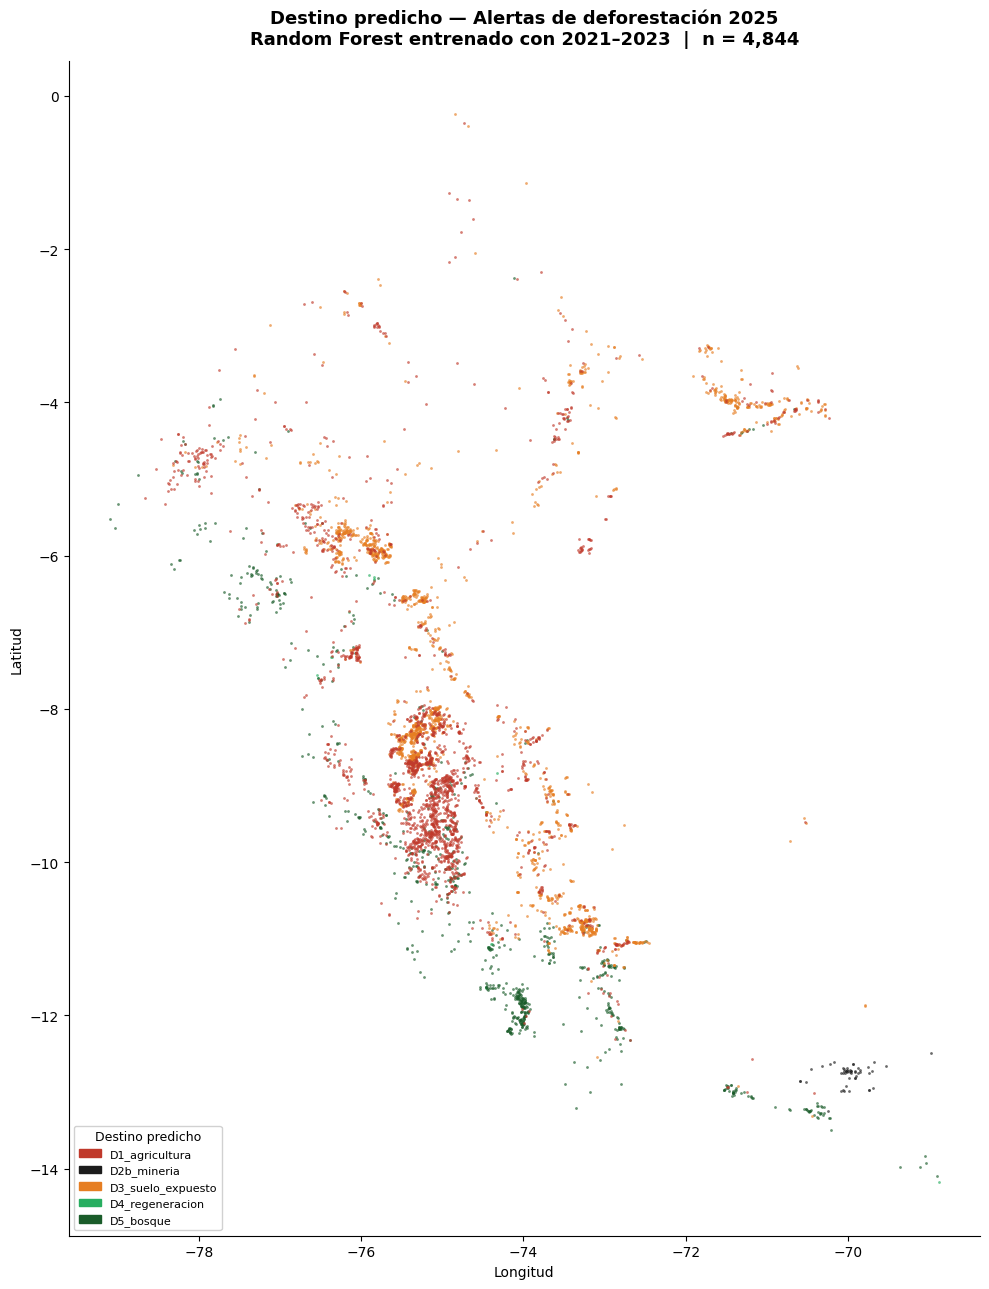

✅ mapa_predicciones_2025.png


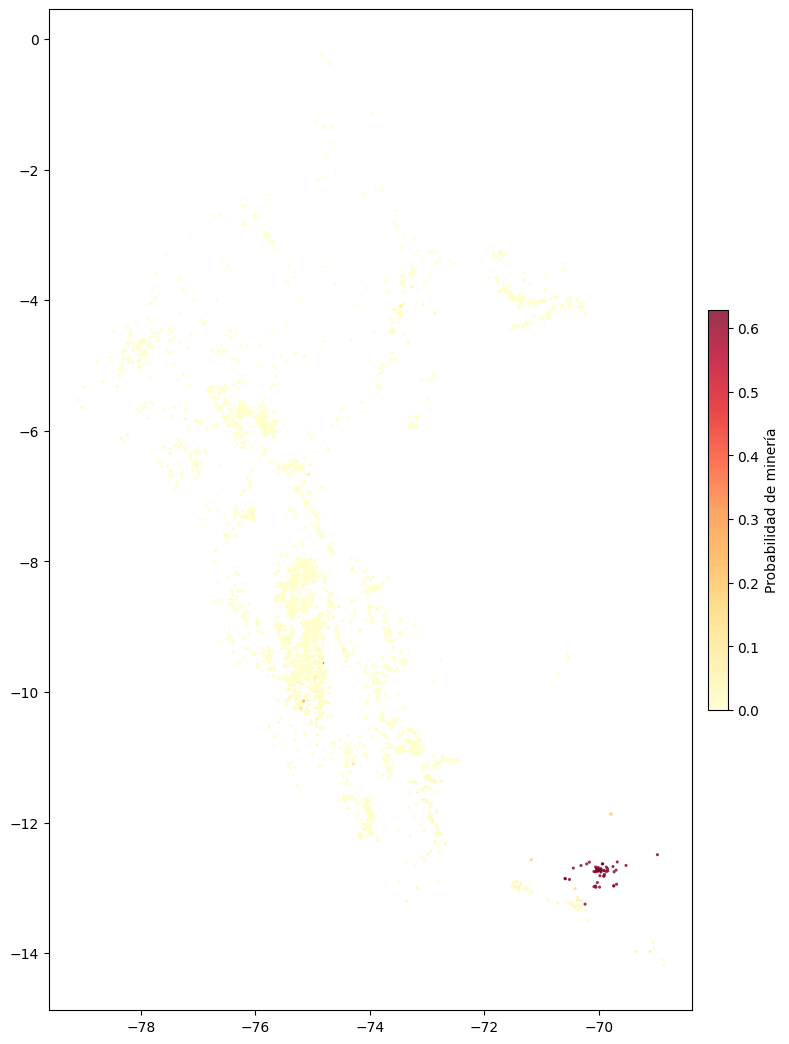

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
from shapely.geometry import Point

COLORES_DEST = {
    'D1_agricultura'    : '#C0392B',
    'D2b_mineria'       : '#1C1C1C',
    'D3_suelo_expuesto' : '#E67E22',
    'D4_regeneracion'   : '#27AE60',
    'D5_bosque'         : '#1A5C2A',
}
DESTINOS = list(COLORES_DEST.keys())

# ── Cargar predicciones 2024 y 2025 ──────────────────────────
pred_2024 = pd.read_csv(RUTA_DATA + "alertas_2024_predicciones_enriquecido.csv")
pred_2025 = pd.read_csv(RUTA_DATA + "alertas_2025_predicciones_enriquecido.csv")

# Añadir centroides desde shapefile
for pred_df, año in [(pred_2024, 2024.0), (pred_2025, 2025.0)]:
    shp_año = shp[shp['ani_lrt'] == año][['alert_d','geometry']].copy()
    shp_año['cx'] = shp_año.geometry.centroid.x
    shp_año['cy'] = shp_año.geometry.centroid.y
    pred_df[['cx','cy']] = pred_df.merge(
        shp_año[['alert_d','cx','cy']], on='alert_d', how='left')[['cx','cy']].values

# ══════════════════════════════════════════════════════════════
# FIGURA 1 — MAPA PREDICCIONES 2024
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(10, 13))

orden_plot = ['D4_regeneracion','D5_bosque','D3_suelo_expuesto',
              'D2b_mineria','D1_agricultura']

for dest in orden_plot:
    sub = pred_2024[pred_2024['destino_predicho'] == dest]
    ax.scatter(sub['cx'], sub['cy'],
               c=COLORES_DEST[dest], s=3, alpha=0.6,
               linewidths=0, label=dest)

ax.set_title('Destino predicho — Alertas de deforestación 2024\n'
             'Random Forest entrenado con 2021–2023',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
ax.spines[['top','right']].set_visible(False)
handles = [mpatches.Patch(color=COLORES_DEST[d], label=d) for d in DESTINOS]
ax.legend(handles=handles, title='Destino predicho',
          fontsize=8, title_fontsize=9, loc='lower left',
          framealpha=0.9, markerscale=3)
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'mapa_predicciones_2024.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ mapa_predicciones_2024.png")

# ══════════════════════════════════════════════════════════════
# FIGURA 2 — MAPA PREDICCIONES 2025
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(10, 13))

for dest in orden_plot:
    sub = pred_2025[pred_2025['destino_predicho'] == dest]
    ax.scatter(sub['cx'], sub['cy'],
               c=COLORES_DEST[dest], s=4, alpha=0.65,
               linewidths=0, label=dest)

ax.set_title('Destino predicho — Alertas de deforestación 2025\n'
             'Random Forest entrenado con 2021–2023  |  n = 4,844',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
ax.spines[['top','right']].set_visible(False)
handles = [mpatches.Patch(color=COLORES_DEST[d], label=d) for d in DESTINOS]
ax.legend(handles=handles, title='Destino predicho',
          fontsize=8, title_fontsize=9, loc='lower left',
          framealpha=0.9, markerscale=3)
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'mapa_predicciones_2025.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ mapa_predicciones_2025.png")

# ══════════════════════════════════════════════════════════════
# FIGURA 3 — MAPA DE CALOR: PROBABILIDAD DE MINERÍA 2025
# (la figura más fuerte para el concurso)
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(10, 13))

sc = ax.scatter(
    pred_2025['cx'], pred_2025['cy'],
    c=pred_2025['prob_D2b_mineria'],
    cmap='YlOrRd',
    s=5, alpha=0.8, linewidths=0,
    vmin=0, vmax=pred_2025['prob_D2b_mineria'].quantile(0.99)
)

cbar = plt.colorbar(sc, ax=ax, shrink=0.4, pad=0.02)
cbar.set_label('Probabilidad de minería')

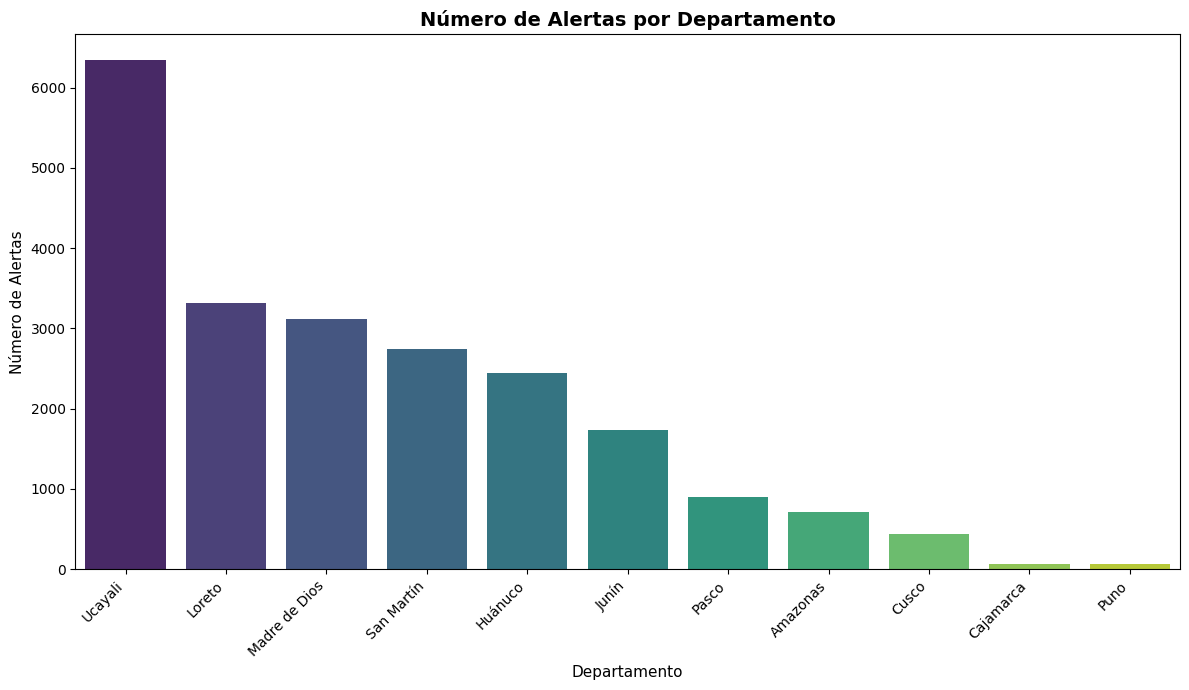

✅ Gráfico de barras de alertas por departamento generado y guardado.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

alert_counts_by_department = df_modelo['dprtmnt'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=alert_counts_by_department.index, y=alert_counts_by_department.values, palette='viridis')
plt.title('Número de Alertas por Departamento', fontsize=14, fontweight='bold')
plt.xlabel('Departamento', fontsize=11)
plt.ylabel('Número de Alertas', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'bar_chart_alerts_by_department.png', dpi=300)
plt.show()
print("✅ Gráfico de barras de alertas por departamento generado y guardado.")

In [ ]:
RUTA = "/content/drive/MyDrive/Proyecto_MapBiomas/"
# ════════════════════════════════════════════════
# EXPORTAR TODOS LOS SHAPEFILES PARA QGIS / ARCGIS PRO
# ════════════════════════════════════════════════
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
import os

# Define shp here as it's used throughout the cell
shp = gpd.read_file(
    "/content/drive/MyDrive/Proyecto_MapBiomas/data_limpia/alertas_con_distancia.shp" # Reverted to .shp
)

RUTA_SHP = RUTA + "shapefiles_output/"
os.makedirs(RUTA_SHP, exist_ok=True)

# ══ 1. TRAYECTORIAS 2021 ─ PUNTOS (centroides) ═══════════
print("Generando SHP 1/4: trayectorias 2021...")

shp_2021 = shp[shp['ani_lrt'] == 2021.0].copy()
shp_2021['cx'] = shp_2021.geometry.centroid.x
shp_2021['cy'] = shp_2021.geometry.centroid.y

tray_shp = shp_2021[['alert_d','area_ha','dprtmnt','cx','cy']].merge(
    df_2021_traj[['alert_d','trayectoria',
                  'destino_T1','destino_T2','destino_T3',
                  'anp_categoria','ti_final',
                  'carretera_cerca','dentro_ANP_dummy']],
    on='alert_d', how='inner'
)

gdf_tray = gpd.GeoDataFrame(
    tray_shp,
    geometry=[Point(x, y) for x, y in zip(tray_shp['cx'], tray_shp['cy'])],
    crs='EPSG:4326'
).drop(columns=['cx','cy'])

# Renombrar a ≤10 chars para shapefile
gdf_tray = gdf_tray.rename(columns={
    'alert_d'        : 'alert_d',
    'area_ha'        : 'area_ha',
    'dprtmnt'        : 'dpto',
    'trayectoria'    : 'trayect',
    'destino_T1'     : 'dest_T1',
    'destino_T2'     : 'dest_T2',
    'destino_T3'     : 'dest_T3',
    'anp_categoria'  : 'anp_categ',
    'ti_final'       : 'ti_final',
    'carretera_cerca': 'carr_cerca',
    'dentro_ANP_dummy': 'en_anp',
})

gdf_tray.to_file(RUTA_SHP + 'trayectorias_2021_puntos.shp',
                 driver='ESRI Shapefile', encoding='utf-8')
print(f"  ✅ {len(gdf_tray):,} puntos → trayectorias_2021_puntos.shp")

# ══ 2. TRAYECTORIAS 2021 ─ POL5GONOS ORIGINALES ════════════
print("Generando SHP 2/4: trayectorias 2021 pol5gonos...")

gdf_tray_poly = shp[shp['ani_lrt'] == 2021.0][['alert_d','area_ha','dprtmnt','geometry']].merge(
    df_2021_traj[['alert_d','trayectoria',
                  'destino_T1','destino_T2','destino_T3',
                  'anp_categoria','ti_final']],
    on='alert_d', how='inner'
)
gdf_tray_poly = gpd.GeoDataFrame(gdf_tray_poly, geometry='geometry', crs='EPSG:4326')
gdf_tray_poly = gdf_tray_poly.rename(columns={
    'dprtmnt'    : 'dpto',
    'trayectoria': 'trayect',
    'destino_T1' : 'dest_T1',
    'destino_T2' : 'dest_T2',
    'destino_T3' : 'dest_T3',
    'anp_categoria': 'anp_categ',
    'ti_final'   : 'ti_final',
})

gdf_tray_poly.to_file(RUTA_SHP + 'trayectorias_2021_poligonos.shp',
                      driver='ESRI Shapefile', encoding='utf-8')
print(f"  ✅ {len(gdf_tray_poly):,} pol5gonos → trayectorias_2021_poligonos.shp")

# ══ 3. PREDICCIONES 2024 ─ POL5GONOS ════════════════
print("Generando SHP 3/4: predicciones 2024...")

pred_2024 = pd.read_csv(RUTA_DATA + "alertas_2024_predicciones_enriquecido.csv")

gdf_2024 = shp[shp['ani_lrt'] == 2024.0][['alert_d','area_ha','dprtmnt','geometry']].merge(
    pred_2024[['alert_d','destino_predicho',
               'prob_D1_agricultura','prob_D2b_mineria',
               'prob_D3_suelo_expuesto','prob_D4_regeneracion','prob_D5_bosque',
               'anp_categoria','ti_final']],
    on='alert_d', how='inner'
)
gdf_2024 = gpd.GeoDataFrame(gdf_2024, geometry='geometry', crs='EPSG:4326')
gdf_2024 = gdf_2024.rename(columns={
    'dprtmnt'              : 'dpto',
    'destino_predicho'     : 'dest_pred',
    'prob_D1_agricultura'  : 'p_agric',
    'prob_D2b_mineria'     : 'p_miner',
    'prob_D3_suelo_expuesto': 'p_suelo',
    'prob_D4_regeneracion' : 'p_regen',
    'prob_D5_bosque'       : 'p_bosque',
    'anp_categoria'        : 'anp_categ',
    'ti_final'             : 'ti_final',
})

gdf_2024.to_file(RUTA_SHP + 'predicciones_2024_poligonos.shp',
                 driver='ESRI Shapefile', encoding='utf-8')
print(f"  ✅ {len(gdf_2024):,} pol5gonos → predicciones_2024_poligonos.shp")

# ══ 4. PREDICCIONES 2025 ─ POL5GONOS ════════════════
print("Generando SHP 4/4: predicciones 2025...")

pred_2025 = pd.read_csv(RUTA_DATA + "alertas_2025_predicciones_enriquecido.csv")

gdf_2025 = shp[shp['ani_lrt'] == 2025.0][['alert_d','area_ha','dprtmnt','geometry']].merge(
    pred_2025[['alert_d','destino_predicho',
               'prob_D1_agricultura','prob_D2b_mineria',
               'prob_D3_suelo_expuesto','prob_D4_regeneracion','prob_D5_bosque',
               'anp_categoria','ti_final']],
    on='alert_d', how='inner'
)
gdf_2025 = gpd.GeoDataFrame(gdf_2025, geometry='geometry', crs='EPSG:4326')
gdf_2025 = gdf_2025.rename(columns={
    'dprtmnt'              : 'dpto',
    'destino_predicho'     : 'dest_pred',
    'prob_D1_agricultura'  : 'p_agric',
    'prob_D2b_mineria'     : 'p_miner',
    'prob_D3_suelo_expuesto': 'p_suelo',
    'prob_D4_regeneracion' : 'p_regen',
    'prob_D5_bosque'       : 'p_bosque',
    'anp_categoria'        : 'anp_categ',
    'ti_final'             : 'ti_final',
})

# Añadir campo de riesgo binario para simbología rápida en QGIS
gdf_2025['riesgo_min'] = (gdf_2025['p_miner'] > 0.5).astype(int)

gdf_2025.to_file(RUTA_SHP + 'predicciones_2025_poligonos.shp',
                 driver='ESRI Shapefile', encoding='utf-8')
print(f"  ✅ {len(gdf_2025):,} pol5gonos → predicciones_2025_poligonos.shp")

# ══ Resumen final ═══════════════════════════
print(f"\n✂️ Todos los SHP en: {RUTA_SHP}")
print("\nArchivos generados:")
archivos = {
    'trayectorias_2021_puntos.shp'   : 'Centroides con trayectoria T1/T2/T3',
    'trayectorias_2021_poligonos.shp': 'Pol5gonos originales con trayectoria',
    'predicciones_2024_poligonos.shp': 'Pol5gonos 2024 con destino predicho + probabilidades',
    'predicciones_2025_poligonos.shp': 'Pol5gonos 2025 con destino predicho + probabilidades + riesgo_min',
}
for f, desc in archivos.items():
    print(f"  {f}")
    print(f"    → {desc}")

Generando SHP 1/4: trayectorias 2021...
  ✅ 7,598 puntos → trayectorias_2021_puntos.shp
Generando SHP 2/4: trayectorias 2021 pol5gonos...
  ✅ 7,598 pol5gonos → trayectorias_2021_poligonos.shp
Generando SHP 3/4: predicciones 2024...
  ✅ 8,783 pol5gonos → predicciones_2024_poligonos.shp
Generando SHP 4/4: predicciones 2025...
  ✅ 4,844 pol5gonos → predicciones_2025_poligonos.shp

✂️ Todos los SHP en: /content/drive/MyDrive/Proyecto_MapBiomas/shapefiles_output/

Archivos generados:
  trayectorias_2021_puntos.shp
    → Centroides con trayectoria T1/T2/T3
  trayectorias_2021_poligonos.shp
    → Pol5gonos originales con trayectoria
  predicciones_2024_poligonos.shp
    → Pol5gonos 2024 con destino predicho + probabilidades
  predicciones_2025_poligonos.shp
    → Pol5gonos 2025 con destino predicho + probabilidades + riesgo_min


In [ ]:
# Función para usar en la Field Calculator de ArcGIS (Python):
# Mapeo de valores truncados a etiquetas completas
def get_full_trajectory_label(trayectoria):
    mapping = {
        "A_consolida": "Consolidación rápida",
        "B_consolida": "Consolidación progresiva",
        "C_consolida": "Consolidación tardía",
        "D_recuperac": "Recuperación sostenida",
        "E_recuperac": "Recuperación post-tránsito",
        "F_reversion": "Reversión post-uso",
        "G_trayector": "Inestable"
    }
    return mapping.get(trayectoria, trayectoria)

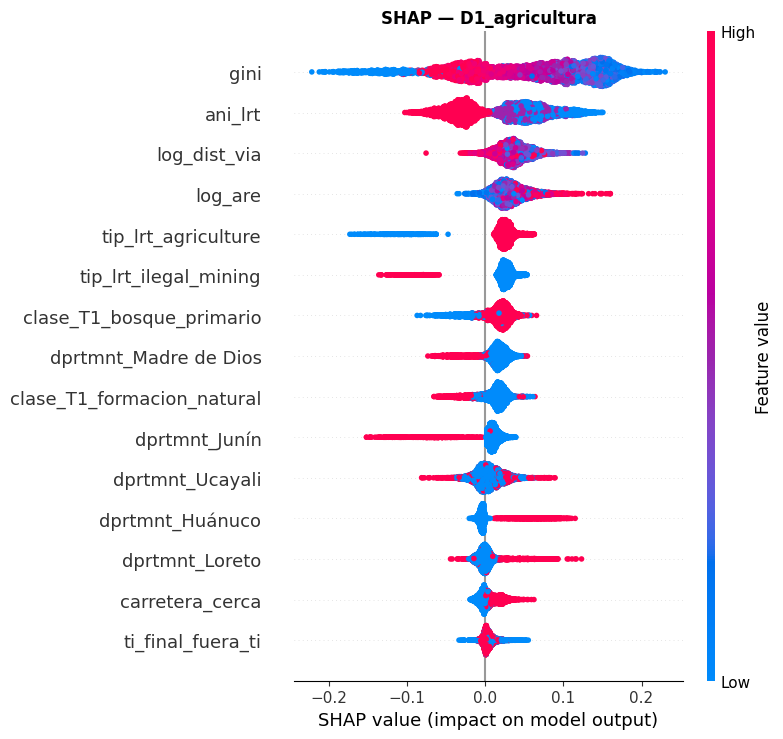

✅ shap_beeswarm_D1.png


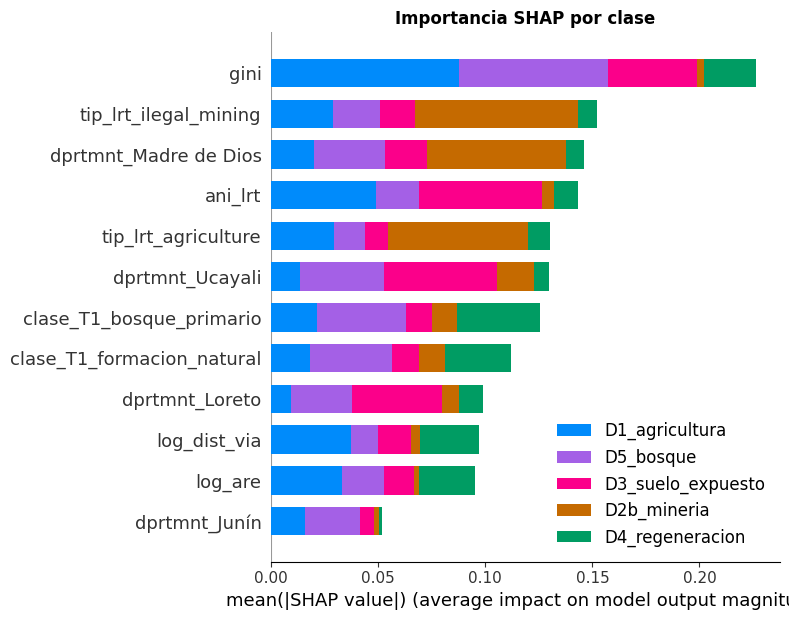

✅ shap_multiclase_bar.png


In [ ]:
import shap

# Usar el RF general (entrenado con todos los datos 2021-2023)
explainer  = shap.TreeExplainer(rf)
shap_vals  = explainer.shap_values(X_test)   # X_test del RF general

# Figura 1 — Beeswarm D1_agricultura
idx_D1 = list(rf.classes_).index('D1_agricultura')
shap.summary_plot(shap_vals[:, :, idx_D1], X_test.values,
                  feature_names=X_test.columns.tolist(), # Añadir feature_names
                  max_display=15, show=False)
plt.title('SHAP — D1_agricultura', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'shap_beeswarm_D1.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ shap_beeswarm_D1.png")

# Figura 2 — Bar multiclase
shap.summary_plot(shap_vals, X_test.values, # Convertir X_test a NumPy array
                  class_names=rf.classes_,
                  plot_type='bar', max_display=12,
                  feature_names=X_test.columns.tolist(), # Añadir feature_names
                  show=False)
plt.title('Importancia SHAP por clase', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RUTA_FIGS + 'shap_multiclase_bar.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ shap_multiclase_bar.png")

In [ ]:
print(df_modelo['dprtmnt'].unique().tolist())

['Cusco', 'Junín', 'Madre de Dios', 'Ucayali', 'Cajamarca', 'Loreto', 'Pasco', 'Amazonas', 'Huánuco', 'Puno', 'San Martín']


In [ ]:
import geopandas as gpd

for nombre, archivo in [
    ('predicciones_2024', 'predicciones_2024_poligonos.shp'),
    ('predicciones_2025', 'predicciones_2025_poligonos.shp')
]:
    gdf = gpd.read_file(RUTA_SHP + archivo)
    gdf_pts = gdf.copy()
    gdf_pts['geometry'] = gdf.geometry.representative_point()
    gdf_pts.to_file(RUTA_SHP + f'{nombre}_puntos.shp',
                    driver='ESRI Shapefile', encoding='utf-8')
    print(f"✅ {nombre}_puntos.shp — {len(gdf_pts):,} puntos")

✅ predicciones_2024_puntos.shp — 8,783 puntos
✅ predicciones_2025_puntos.shp — 4,844 puntos
